# 07 — 10-Split Energy Prediction Robustness Evaluation

Trains LSTM and BiLSTM on all 10 random splits to get stable mean ± std MAE.
After training, runs the same evaluation suite as notebook 06:
Wilcoxon tests, RFT analysis, overprediction safety check, and abnormal flight taxonomy.


In [9]:
import os, gc, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import psutil
import shap
from pathlib import Path
from scipy.stats import wilcoxon
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
FOLDER_VER    = "v3_voltage_random10_issue_flight-removed"
FILE_VER      = "v4_voltage_random10_cleaned"
DATA_DIR      = BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}"
CNN_SCORE_DIR = BASE_DIR / "model_outputs" / f"cnn_lstm_ae_anomaly_score_{FOLDER_VER}"
OUTPUT_DIR    = BASE_DIR / "model_outputs" / "07_10split_energy"
PLOT_DIR      = OUTPUT_DIR / "plots"
RFT_PLOT_DIR  = PLOT_DIR / "rft_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
RFT_PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "target_energy_next_60s_wh"

BASE_FEATURES = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

FEATURE_SETS = {
    "Base_13":           BASE_FEATURES,
    "Base_13+CNN_Score": BASE_FEATURES + ["anomaly_score_cnn"],
}

SPLITS = [
    ("split_01_seed_11",  11),
    ("split_02_seed_22",  22),
    ("split_03_seed_33",  33),
    ("split_04_seed_44",  44),
    ("split_05_seed_55",  55),
    ("split_06_seed_66",  66),
    ("split_07_seed_77",  77),
    ("split_08_seed_88",  88),
    ("split_09_seed_99",  99),
    ("split_10_seed_111", 111),
]

PRIMARY_SPLIT = "split_05_seed_55"

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(f"Device : {device}")
print(f"RAM    : {psutil.virtual_memory().available/1e9:.1f} GB free")
print(f"Splits : {len(SPLITS)}")


Device : mps
RAM    : 3.0 GB free
Splits : 10


In [10]:
SEQ_LEN    = 30
BATCH_SIZE = 512
EPOCHS     = 50
PATIENCE   = 10


class FastFlightDataset(torch.utils.data.Dataset):
   
    def __init__(self, df, feat_cols, target, seq_len):
        seqs, tgts = [], []
        for _, grp in df.sort_values(["log_id","time_s"]).groupby("log_id", sort=False):
            X = grp[feat_cols].to_numpy(dtype=np.float32)
            y = grp[target].to_numpy(dtype=np.float32)
            n = len(X)
            if n <= seq_len:
                continue
            for i in range(seq_len, n):
                seqs.append(X[i-seq_len:i])
                tgts.append(y[i])
        self.X = torch.from_numpy(np.array(seqs, dtype=np.float32))
        self.y = torch.from_numpy(np.array(tgts, dtype=np.float32))

    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class BiLSTMRegressor(nn.Module):
    
    def __init__(self, input_size, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Linear(hidden*2, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_seq_model(model, train_ds, val_ds, ckpt_path, seed,
                    epochs=EPOCHS, patience=PATIENCE):
    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=g)
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=0)

    best_val, pat_ctr = np.inf, 0

    for epoch in range(1, epochs+1):
        model.train()
        tl = []
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tl.append(loss.item())
        t_loss = np.mean(tl)

        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                vl.append(criterion(model(xb.to(device)), yb.to(device)).item())
        v_loss = np.mean(vl)
        scheduler.step(v_loss)

        print(f"  Ep {epoch:02d} | Train:{t_loss:.5f} Val:{v_loss:.5f}")

        if v_loss < best_val - 1e-5:
            best_val, pat_ctr = v_loss, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                print(f"    Early stop ep {epoch}  best_val={best_val:.5f}")
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    return model, best_val


def predict_seq(model, df, feat_cols, target, seq_len):
    model.eval()
    records = []
    for lid, grp in df.sort_values(["log_id","time_s"]).groupby("log_id"):
        X   = grp[feat_cols].to_numpy(dtype=np.float32)
        y   = grp[target].to_numpy(dtype=np.float32)
        t   = grp["time_s"].to_numpy()
        lbl = grp["dataset_label"].iloc[0]
        n   = len(X)
        if n <= seq_len: continue
        seqs = np.stack([X[i-seq_len:i] for i in range(seq_len, n)])
        preds = []
        with torch.no_grad():
            for batch in torch.split(torch.tensor(seqs), BATCH_SIZE):
                preds.extend(model(batch.to(device)).cpu().numpy().tolist())
        for p, yt, ts in zip(preds, y[seq_len:], t[seq_len:]):
            records.append({"log_id": lid, "dataset_label": lbl,
                            "time_s": ts, "y_true": float(yt), "y_pred": float(p)})
    return pd.DataFrame(records)


def evaluate(y_true, y_pred, label="ALL"):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    errors = y_true - y_pred
    return {
        "label":          label,
        "MAE_Wh":         round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE_Wh":        round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "R2":             round(r2_score(y_true, y_pred), 4),
        "P95_error_Wh":   round(float(np.percentile(np.abs(errors), 95)), 4),
        "Underpredict_%": round((y_pred < y_true).mean() * 100, 2),
        "n_rows":         len(y_true),
    }

print(f"Model definitions ready  SEQ_LEN={SEQ_LEN}  EPOCHS={EPOCHS}  PATIENCE={PATIENCE}")


Model definitions ready  SEQ_LEN=30  EPOCHS=50  PATIENCE=10


In [12]:

all_split_results = []
all_seq_preds = {
    "LSTM_Base_13":             [],
    "LSTM_Base_13+CNN_Score":   [],
    "BiLSTM_Base_13":           [],
    "BiLSTM_Base_13+CNN_Score": [],
}
primary_seq_preds = {
    "LSTM_Base_13":             None,
    "LSTM_Base_13+CNN_Score":   None,
    "BiLSTM_Base_13":           None,
    "BiLSTM_Base_13+CNN_Score": None,
}
primary_test_df = None

for split_name, seed in SPLITS:
    print(f"\n{'='*60}")
    print(f"SPLIT: {split_name}  SEED: {seed}")
    print(f"{'='*60}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

    split_dir = DATA_DIR / split_name
    cnn_dir   = CNN_SCORE_DIR / split_name

    train_df = pd.read_parquet(
        split_dir / f"train_no_dr_scaled_{FILE_VER}_{split_name}.parquet")
    val_df = pd.read_parquet(
        split_dir / f"val_no_dr_scaled_{FILE_VER}_{split_name}.parquet")
    test_df = pd.read_parquet(
        split_dir / f"test_no_dr_scaled_{FILE_VER}_{split_name}.parquet")

    cnn_file = cnn_dir / f"test_cnn_lstm_ae_scored_{split_name}.parquet"
    cnn_test = pd.read_parquet(cnn_file, columns=["log_id","time_s","anomaly_score_cnn"])
    test_df  = test_df.sort_values(["log_id","time_s"]).reset_index(drop=True)
    cnn_test = cnn_test.sort_values(["log_id","time_s"]).reset_index(drop=True)

    if len(test_df) == len(cnn_test):
        test_df["anomaly_score_cnn"] = cnn_test["anomaly_score_cnn"].values.astype(np.float32)
        print(f"  CNN scores merged  ({len(test_df):,} rows)")
    else:
        print(f"  WARNING: row mismatch — using zeros")
        test_df["anomaly_score_cnn"] = np.float32(0.0)

    for df in [train_df, val_df]:
        df["anomaly_score_cnn"] = np.float32(0.0)

    for df in [train_df, val_df, test_df]:
        for col in df.select_dtypes("float64").columns:
            df[col] = df[col].astype(np.float32)

    print(f"  Train:{train_df.shape} Val:{val_df.shape} Test:{test_df.shape}")

    for feat_name, feat_cols in FEATURE_SETS.items():
        available = [f for f in feat_cols if f in train_df.columns]

        train_ds = FastFlightDataset(train_df, available, TARGET, SEQ_LEN)
        val_ds   = FastFlightDataset(val_df,   available, TARGET, SEQ_LEN)

        for arch_name, ModelClass in [("LSTM", LSTMRegressor), ("BiLSTM", BiLSTMRegressor)]:
            run = f"{arch_name}_{feat_name}_{split_name}"

            torch.manual_seed(seed)
            np.random.seed(seed)
            random.seed(seed)

            model = ModelClass(input_size=len(available)).to(device)

            ckpt_dir  = OUTPUT_DIR / f"checkpoints_{split_name}"
            ckpt_dir.mkdir(parents=True, exist_ok=True)
            ckpt_path = ckpt_dir / f"ckpt_{arch_name}_{feat_name}.pt"

            if ckpt_path.exists():
                print(f"  SKIP (already done): {arch_name} {feat_name}")
                model.load_state_dict(
                    torch.load(ckpt_path, map_location=device, weights_only=True))
                model.eval()
            else:
                print(f"  Training: {run}")
                model, best_val = train_seq_model(model, train_ds, val_ds, ckpt_path, seed)
            #Model predicts on test flights
            pred_df = predict_seq(model, test_df, available, TARGET, SEQ_LEN)
            pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)


            run_key = f"{arch_name}_{feat_name}"
            all_seq_preds[run_key].append(pred_df.copy())
            primary_seq_preds[run_key] = pred_df.copy()
            if primary_test_df is None:
                primary_test_df = test_df.copy()

            for lbl in ["normal","abnormal"]:
                mask = pred_df["dataset_label"] == lbl
                if mask.sum() == 0: continue
                #MAE computed from those predictions
                mae  = mean_absolute_error(pred_df.loc[mask,"y_true"], pred_df.loc[mask,"y_pred"])
                rmse = np.sqrt(mean_squared_error(pred_df.loc[mask,"y_true"], pred_df.loc[mask,"y_pred"]))
                all_split_results.append({
                    "split"      : split_name,
                    "seed"       : seed,
                    "model"      : arch_name,
                    "feature_set": feat_name,
                    "flight_type": lbl,
                    "MAE_Wh"     : round(mae,  4),
                    "RMSE_Wh"    : round(rmse, 4),
                })
                print(f"    {arch_name} {feat_name} — {lbl.upper()} MAE: {mae:.4f} Wh")

            del model; gc.collect()
            if device.type == "mps": torch.mps.empty_cache()

        del train_ds, val_ds; gc.collect()

    del train_df, val_df, test_df, cnn_test; gc.collect()

results_df = pd.DataFrame(all_split_results)
results_df.to_csv(OUTPUT_DIR / "10split_raw_results.csv", index=False)
print(f"\nDone. {len(results_df)} result rows saved.")
pooled_seq_preds = {}
for run_key, dfs in all_seq_preds.items():
    pooled_seq_preds[run_key] = pd.concat(dfs, ignore_index=True)
    print(f"{run_key}: {len(pooled_seq_preds[run_key]):,} rows pooled")
print(f"Primary split predictions stored: {list(primary_seq_preds.keys())}")



SPLIT: split_01_seed_11  SEED: 11
  CNN scores merged  (134,655 rows)
  Train:(698993, 18) Val:(133277, 18) Test:(134655, 18)
  SKIP (already done): LSTM Base_13
    LSTM Base_13 — NORMAL MAE: 0.2306 Wh
    LSTM Base_13 — ABNORMAL MAE: 1.0379 Wh
  SKIP (already done): BiLSTM Base_13
    BiLSTM Base_13 — NORMAL MAE: 0.2665 Wh
    BiLSTM Base_13 — ABNORMAL MAE: 1.0672 Wh
  SKIP (already done): LSTM Base_13+CNN_Score
    LSTM Base_13+CNN_Score — NORMAL MAE: 0.3053 Wh
    LSTM Base_13+CNN_Score — ABNORMAL MAE: 1.3778 Wh
  SKIP (already done): BiLSTM Base_13+CNN_Score
    BiLSTM Base_13+CNN_Score — NORMAL MAE: 0.2942 Wh
    BiLSTM Base_13+CNN_Score — ABNORMAL MAE: 1.0536 Wh

SPLIT: split_02_seed_22  SEED: 22
  CNN scores merged  (136,187 rows)
  Train:(708862, 18) Val:(121876, 18) Test:(136187, 18)
  SKIP (already done): LSTM Base_13
    LSTM Base_13 — NORMAL MAE: 0.6520 Wh
    LSTM Base_13 — ABNORMAL MAE: 0.5053 Wh
  SKIP (already done): BiLSTM Base_13
    BiLSTM Base_13 — NORMAL MAE: 0.4

In [13]:
results_df = pd.read_csv(OUTPUT_DIR / "10split_raw_results.csv")

summary = (results_df
    .groupby(["model","feature_set","flight_type"])["MAE_Wh"]
    .agg(mean="mean", std="std", min="min", max="max")
    .round(4)
    .reset_index()
)

print("="*70)
print("10-SPLIT MEAN ± STD MAE — LSTM AND BiLSTM")
print("="*70)

for ftype in ["normal","abnormal"]:
    sub = summary[summary["flight_type"]==ftype].sort_values("mean").reset_index(drop=True)
    sub.index += 1
    print(f"\n--- {ftype.upper()} FLIGHTS ---")
    print(sub[["model","feature_set","mean","std","min","max"]].to_string())

print("\n" + "="*70)
print("KEY FINDING: CNN score effect on ABNORMAL flights (mean across 10 splits)")
print("="*70)
abn = summary[summary["flight_type"]=="abnormal"]
for model in ["LSTM","BiLSTM"]:
    base = float(abn[(abn["model"]==model) & (abn["feature_set"]=="Base_13")]["mean"])
    cnn  = float(abn[(abn["model"]==model) & (abn["feature_set"]=="Base_13+CNN_Score")]["mean"])
    diff = base - cnn
    verdict = "IMPROVES" if diff > 0.01 else ("WORSENS" if diff < -0.01 else "NO CHANGE")
    print(f"  {model:<8}  Base:{base:.4f}  +CNN:{cnn:.4f}  delta={diff:+.4f}  {verdict}")


10-SPLIT MEAN ± STD MAE — LSTM AND BiLSTM

--- NORMAL FLIGHTS ---
    model        feature_set    mean     std     min     max
1  BiLSTM            Base_13  0.2913  0.1488  0.1495  0.5607
2  BiLSTM  Base_13+CNN_Score  0.3160  0.1723  0.1536  0.6053
3    LSTM            Base_13  0.3228  0.2043  0.1535  0.6520
4    LSTM  Base_13+CNN_Score  0.3362  0.2482  0.1357  0.8982

--- ABNORMAL FLIGHTS ---
    model        feature_set    mean     std     min     max
1  BiLSTM            Base_13  1.2344  1.1393  0.2857  4.2019
2    LSTM            Base_13  1.2950  1.3211  0.2979  4.8374
3  BiLSTM  Base_13+CNN_Score  1.3127  1.7126  0.2631  6.1075
4    LSTM  Base_13+CNN_Score  1.5480  1.8212  0.2638  6.4327

KEY FINDING: CNN score effect on ABNORMAL flights (mean across 10 splits)
  LSTM      Base:1.2950  +CNN:1.5480  delta=-0.2530  WORSENS
  BiLSTM    Base:1.2344  +CNN:1.3127  delta=-0.0783  WORSENS


In [14]:
# 9-split summary — excluding split_06_seed_66
results_no06 = results_df[results_df["split"] != "split_06_seed_66"]

summary_no06 = (results_no06
    .groupby(["model","feature_set","flight_type"])["MAE_Wh"]
    .agg(mean="mean", std="std", min="min", max="max")
    .round(4)
    .reset_index()
)

print("="*70)
print("9-SPLIT MEAN ± STD MAE — EXCLUDING split_06 (outlier: flight 3d552044)")
print("="*70)

for ftype in ["normal","abnormal"]:
    sub = summary_no06[summary_no06["flight_type"]==ftype].sort_values("mean").reset_index(drop=True)
    sub.index += 1
    print(f"\n--- {ftype.upper()} FLIGHTS ---")
    print(sub[["model","feature_set","mean","std","min","max"]].to_string())

print("\n" + "="*70)
print("KEY FINDING: CNN score effect on ABNORMAL flights (9 splits)")
print("="*70)
abn9 = summary_no06[summary_no06["flight_type"]=="abnormal"]
for model in ["LSTM","BiLSTM"]:
    base = float(abn9[(abn9["model"]==model) & (abn9["feature_set"]=="Base_13")]["mean"])
    cnn  = float(abn9[(abn9["model"]==model) & (abn9["feature_set"]=="Base_13+CNN_Score")]["mean"])
    diff = base - cnn
    verdict = "IMPROVES" if diff > 0.01 else ("WORSENS" if diff < -0.01 else "NO CHANGE")
    print(f"  {model:<8}  Base:{base:.4f}  +CNN:{cnn:.4f}  delta={diff:+.4f}  {verdict}")

# side by side comparison
print("\n" + "="*70)
print("SIDE BY SIDE — 10 splits vs 9 splits (abnormal only)")
print("="*70)
abn10 = summary[summary["flight_type"]=="abnormal"]
for model in ["LSTM","BiLSTM"]:
    for feat in ["Base_13","Base_13+CNN_Score"]:
        m10 = float(abn10[(abn10["model"]==model) & (abn10["feature_set"]==feat)]["mean"])
        s10 = float(abn10[(abn10["model"]==model) & (abn10["feature_set"]==feat)]["std"])
        m9  = float(abn9[(abn9["model"]==model) & (abn9["feature_set"]==feat)]["mean"])
        s9  = float(abn9[(abn9["model"]==model) & (abn9["feature_set"]==feat)]["std"])
        print(f"  {model} {feat:<22} "
              f"10-split: {m10:.3f}±{s10:.3f}  "
              f"9-split: {m9:.3f}±{s9:.3f}")

9-SPLIT MEAN ± STD MAE — EXCLUDING split_06 (outlier: flight 3d552044)

--- NORMAL FLIGHTS ---
    model        feature_set    mean     std     min     max
1  BiLSTM            Base_13  0.3071  0.1487  0.1577  0.5607
2  BiLSTM  Base_13+CNN_Score  0.3334  0.1733  0.1536  0.6053
3    LSTM            Base_13  0.3412  0.2077  0.1535  0.6520
4    LSTM  Base_13+CNN_Score  0.3567  0.2542  0.1357  0.8982

--- ABNORMAL FLIGHTS ---
    model        feature_set    mean     std     min     max
1  BiLSTM  Base_13+CNN_Score  0.7800  0.3265  0.2631  1.2265
2    LSTM            Base_13  0.9014  0.4698  0.2979  1.7704
3  BiLSTM            Base_13  0.9046  0.4870  0.2857  1.7834
4    LSTM  Base_13+CNN_Score  1.0052  0.6461  0.2638  2.1734

KEY FINDING: CNN score effect on ABNORMAL flights (9 splits)
  LSTM      Base:0.9014  +CNN:1.0052  delta=-0.1038  WORSENS
  BiLSTM    Base:0.9046  +CNN:0.7800  delta=+0.1246  IMPROVES

SIDE BY SIDE — 10 splits vs 9 splits (abnormal only)
  LSTM Base_13                

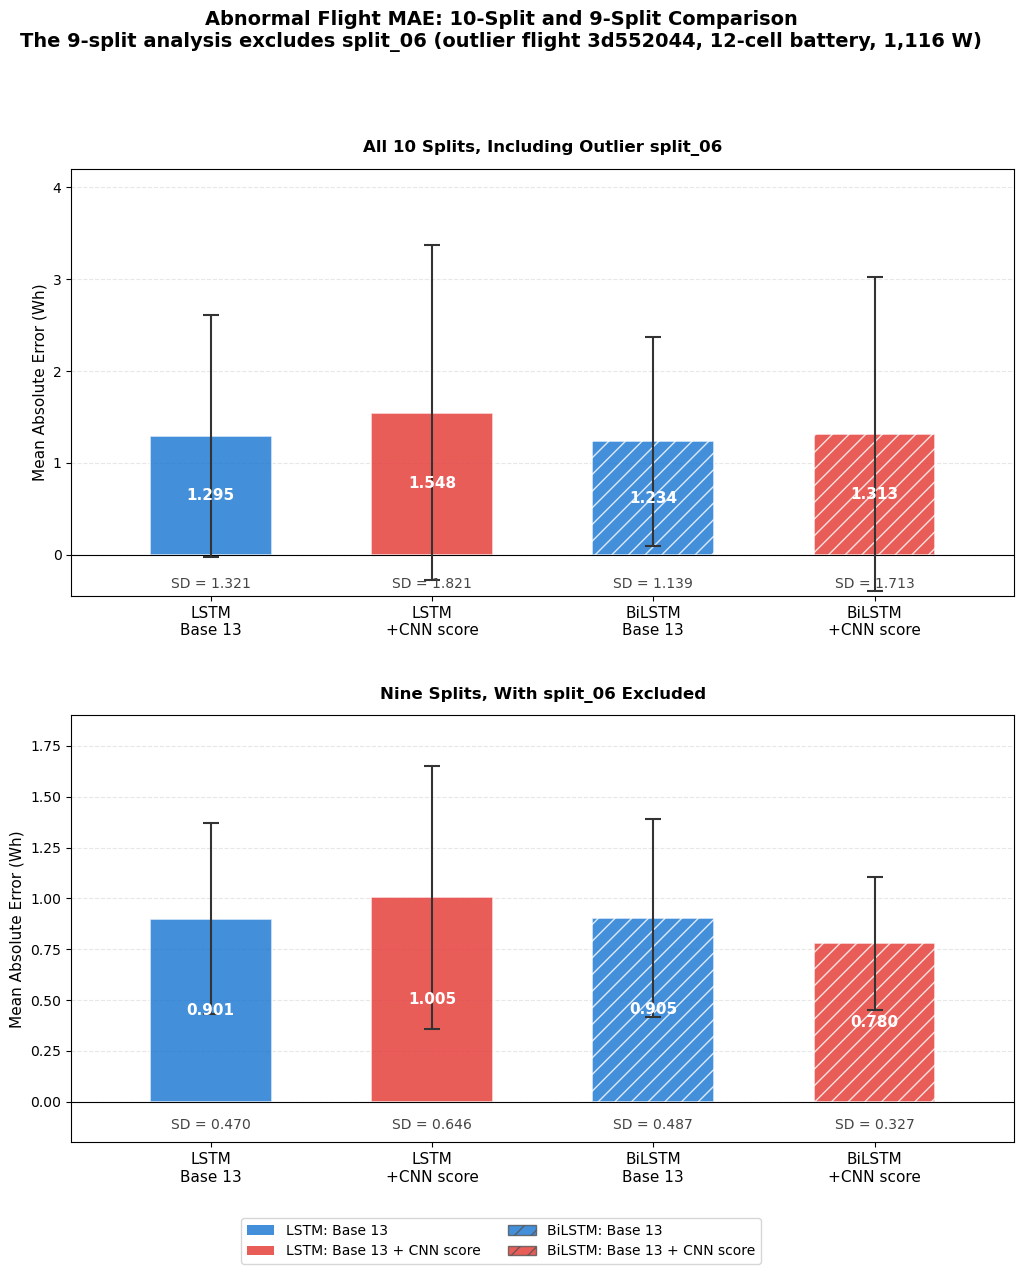

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/07_10split_energy/plots/10split_vs_9split_comparison.png


In [15]:
# ── plot: charts placed vertically for better readability ─────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Ensure that normal chart text is at least 10 pt
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

labels = [
    "LSTM\nBase 13",
    "LSTM\n+CNN score",
    "BiLSTM\nBase 13",
    "BiLSTM\n+CNN score",
]

means_10 = [1.295, 1.548, 1.234, 1.313]
stds_10 = [1.321, 1.821, 1.139, 1.713]

means_9 = [0.901, 1.005, 0.905, 0.780]
stds_9 = [0.470, 0.646, 0.487, 0.327]

colors = ["#1976D2", "#E53935", "#1976D2", "#E53935"]
hatches = ["", "", "//", "//"]

x = np.arange(len(labels))
bar_width = 0.55

# Two rows and one column
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 13),
)

fig.suptitle(
    "Abnormal Flight MAE: 10-Split and 9-Split Comparison\n"
    "The 9-split analysis excludes split_06 "
    "(outlier flight 3d552044, 12-cell battery, 1,116 W)",
    fontsize=14,
    fontweight="bold",
    y=0.985,
)

plot_details = [
    {
        "means": means_10,
        "stds": stds_10,
        "title": "All 10 Splits, Including Outlier split_06",
        "ylim": (-0.45, 4.2),
    },
    {
        "means": means_9,
        "stds": stds_9,
        "title": "Nine Splits, With split_06 Excluded",
        "ylim": (-0.20, 1.90),
    },
]

for ax, details in zip(axes, plot_details):

    means = details["means"]
    stds = details["stds"]

    bars = ax.bar(
        x,
        means,
        bar_width,
        color=colors,
        alpha=0.82,
        hatch=hatches,
        edgecolor="white",
        linewidth=1.2,
        zorder=2,
    )

    ax.errorbar(
        x,
        means,
        yerr=stds,
        fmt="none",
        color="#333333",
        capsize=6,
        capthick=1.5,
        elinewidth=1.5,
        zorder=3,
    )

    # Add mean value inside each bar
    for bar, mean_value in zip(bars, means):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            mean_value * 0.50,
            f"{mean_value:.3f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white",
        )

    # Add standard deviation below each category
    for position, std_value in enumerate(stds):
        ax.text(
            position,
            details["ylim"][0] + 0.05,
            f"SD = {std_value:.3f}",
            ha="center",
            va="bottom",
            fontsize=10,
            color="#444444",
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11)

    ax.set_ylabel("Mean Absolute Error (Wh)", fontsize=11)
    ax.set_title(
        details["title"],
        fontsize=12,
        fontweight="bold",
        pad=12,
    )

    ax.set_ylim(details["ylim"])

    ax.grid(
        axis="y",
        alpha=0.30,
        linestyle="--",
        zorder=0,
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    # Add more horizontal spacing
    ax.margins(x=0.10)


# ── legend ────────────────────────────────────────────────────

legend_elements = [
    mpatches.Patch(
        facecolor="#1976D2",
        alpha=0.82,
        label="LSTM: Base 13",
    ),
    mpatches.Patch(
        facecolor="#E53935",
        alpha=0.82,
        label="LSTM: Base 13 + CNN score",
    ),
    mpatches.Patch(
        facecolor="#1976D2",
        alpha=0.82,
        hatch="//",
        edgecolor="#555555",
        label="BiLSTM: Base 13",
    ),
    mpatches.Patch(
        facecolor="#E53935",
        alpha=0.82,
        hatch="//",
        edgecolor="#555555",
        label="BiLSTM: Base 13 + CNN score",
    ),
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    fontsize=10,
    frameon=True,
    bbox_to_anchor=(0.5, 0.015),
)

# Leave enough room for the main title and legend
plt.tight_layout(
    rect=[0.04, 0.07, 0.98, 0.94],
    h_pad=3.5,
)

output_path = PLOT_DIR / "10split_vs_9split_comparison.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Saved: {output_path}")

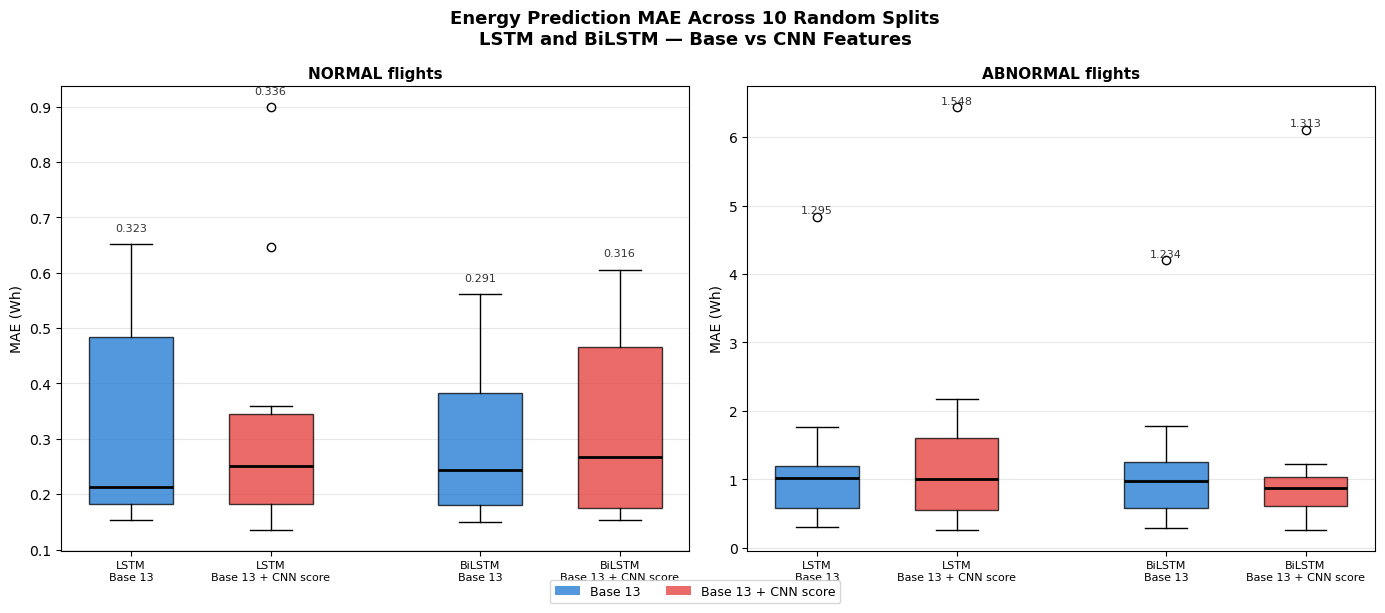

Saved: 10split_mae_boxplot.png


In [16]:
results_df = pd.read_csv(OUTPUT_DIR / "10split_raw_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    "Energy Prediction MAE Across 10 Random Splits\nLSTM and BiLSTM — Base vs CNN Features",
    fontsize=13, fontweight="bold"
)

colors = {"Base_13": "#1976D2", "Base_13+CNN_Score": "#E53935"}
labels = {"Base_13": "Base 13", "Base_13+CNN_Score": "Base 13 + CNN score"}

for ax, ftype in zip(axes, ["normal","abnormal"]):
    sub = results_df[results_df["flight_type"]==ftype]
    positions, data, tick_labels = [], [], []
    pos = 1

    for model in ["LSTM","BiLSTM"]:
        for feat in ["Base_13","Base_13+CNN_Score"]:
            vals = sub[(sub["model"]==model) & (sub["feature_set"]==feat)]["MAE_Wh"].values
            data.append(vals)
            positions.append(pos)
            tick_labels.append(f"{model}\n{labels[feat]}")
            pos += 1
        pos += 0.5

    bp = ax.boxplot(data, positions=positions, patch_artist=True,
                    widths=0.6, medianprops=dict(color="black", linewidth=2))

    feat_cycle = ["Base_13","Base_13+CNN_Score","Base_13","Base_13+CNN_Score"]
    for patch, feat in zip(bp["boxes"], feat_cycle):
        patch.set_facecolor(colors[feat])
        patch.set_alpha(0.75)

    for pos_i, vals in zip(positions, data):
        ax.text(pos_i, max(vals)+0.02, f"{np.mean(vals):.3f}",
                ha="center", va="bottom", fontsize=8, color="#333")

    ax.set_title(f"{ftype.upper()} flights", fontsize=11, fontweight="bold")
    ax.set_ylabel("MAE (Wh)", fontsize=10)
    ax.set_xticks(positions)
    ax.set_xticklabels(tick_labels, fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[f], alpha=0.75, label=labels[f])
                   for f in ["Base_13","Base_13+CNN_Score"]]
fig.legend(handles=legend_elements, loc="lower center", ncol=2,
           fontsize=9, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig(PLOT_DIR / "10split_mae_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: 10split_mae_boxplot.png")


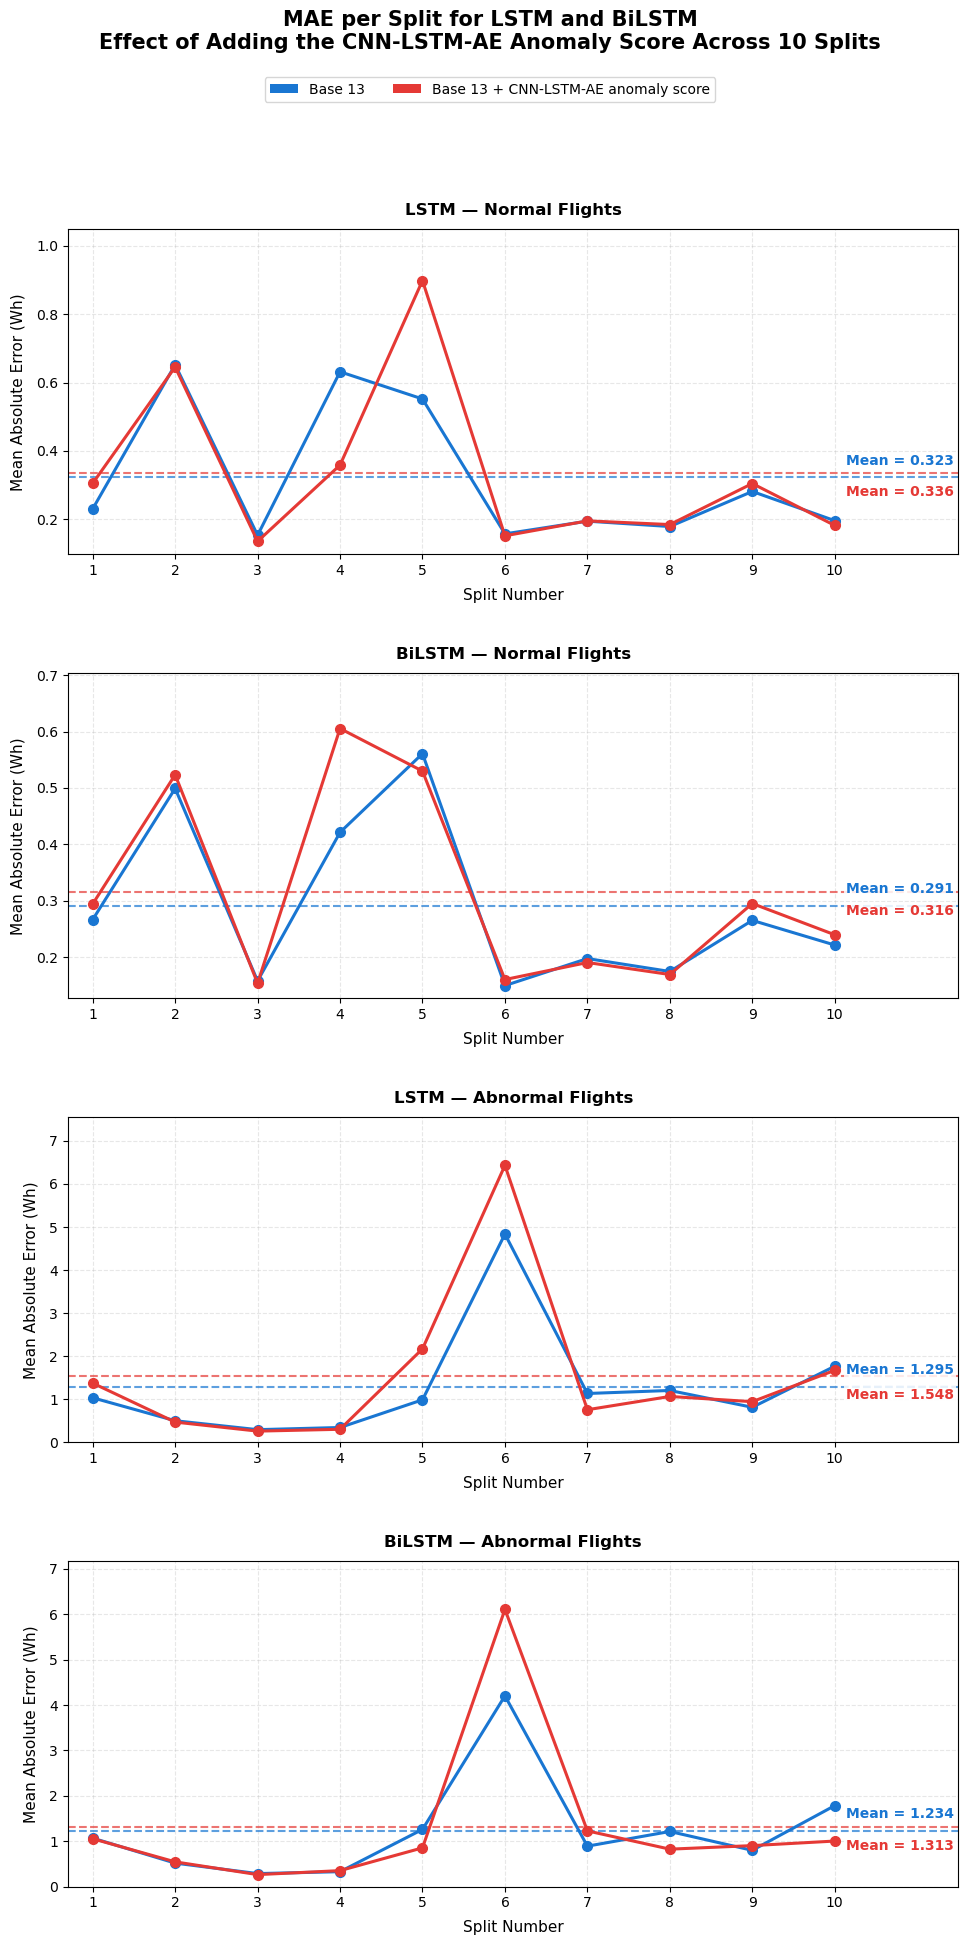

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/07_10split_energy/plots/10split_mae_per_split.png


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Load results ──────────────────────────────────────────────
results_df = pd.read_csv(OUTPUT_DIR / "10split_raw_results.csv")

# ── Font settings ─────────────────────────────────────────────
# All important text is at least 10 pt.
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

# ── Plot settings ─────────────────────────────────────────────
colors_feat = {
    "Base_13": "#1976D2",
    "Base_13+CNN_Score": "#E53935",
}

feature_labels = {
    "Base_13": "Base 13",
    "Base_13+CNN_Score": "Base 13 + CNN-LSTM-AE anomaly score",
}

plot_order = [
    ("LSTM", "normal", "LSTM — Normal Flights"),
    ("BiLSTM", "normal", "BiLSTM — Normal Flights"),
    ("LSTM", "abnormal", "LSTM — Abnormal Flights"),
    ("BiLSTM", "abnormal", "BiLSTM — Abnormal Flights"),
]

# Vertical offsets prevent the two mean labels from overlapping.
mean_label_offsets = {
    "Base_13": 12,             # Blue label moves upward
    "Base_13+CNN_Score": -14,  # Red label moves downward
}

# ── Create four vertically arranged plots ─────────────────────
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(11, 20),
)

fig.suptitle(
    "MAE per Split for LSTM and BiLSTM\n"
    "Effect of Adding the CNN-LSTM-AE Anomaly Score Across 10 Splits",
    fontsize=15,
    fontweight="bold",
    y=0.995,
)

for ax, (model, flight_type, title) in zip(axes, plot_order):

    sub = results_df[
        (results_df["model"] == model)
        & (results_df["flight_type"] == flight_type)
    ].copy()

    # Store mean values so they can be used when adjusting the y-axis.
    mean_values = []

    for feature_set in ["Base_13", "Base_13+CNN_Score"]:

        series = (
            sub[sub["feature_set"] == feature_set]
            .sort_values("seed")
            .reset_index(drop=True)
        )

        if series.empty:
            print(
                f"Warning: No results found for "
                f"{model}, {flight_type}, {feature_set}"
            )
            continue

        x_values = np.arange(1, len(series) + 1)
        mae_values = series["MAE_Wh"].to_numpy()
        mean_mae = mae_values.mean()

        mean_values.append(mean_mae)

        # Plot split-level MAE values.
        ax.plot(
            x_values,
            mae_values,
            marker="o",
            linewidth=2.2,
            markersize=7,
            color=colors_feat[feature_set],
            label=feature_labels[feature_set],
            zorder=3,
        )

        # Plot the mean MAE as a dashed horizontal line.
        ax.axhline(
            y=mean_mae,
            color=colors_feat[feature_set],
            linewidth=1.5,
            linestyle="--",
            alpha=0.70,
            zorder=2,
        )

        # Add the mean label with a vertical offset.
        # The blue label is placed above its line and the red below.
        ax.annotate(
            f"Mean = {mean_mae:.3f}",
            xy=(len(series), mean_mae),
            xytext=(8, mean_label_offsets[feature_set]),
            textcoords="offset points",
            color=colors_feat[feature_set],
            fontsize=10,
            fontweight="bold",
            ha="left",
            va="center",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
                "pad": 1.5,
            },
            clip_on=False,
            zorder=4,
        )

    # ── Axis formatting ───────────────────────────────────────
    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=10,
    )

    ax.set_xlabel(
        "Split Number",
        fontsize=11,
        labelpad=7,
    )

    ax.set_ylabel(
        "Mean Absolute Error (Wh)",
        fontsize=11,
        labelpad=8,
    )

    ax.set_xticks(range(1, 11))

    # Extra space on the right for the mean labels.
    ax.set_xlim(0.7, 11.5)

    ax.grid(
        axis="both",
        linestyle="--",
        alpha=0.30,
        linewidth=0.8,
        zorder=0,
    )

    ax.tick_params(
        axis="both",
        labelsize=10,
    )

    # Keep the lower boundary above zero while adding space at the top.
    current_bottom, current_top = ax.get_ylim()

    if flight_type == "normal":
        lower_limit = max(0, current_bottom)
    else:
        lower_limit = 0

    ax.set_ylim(
        lower_limit,
        current_top * 1.12,
    )

# ── Shared legend ─────────────────────────────────────────────
legend_elements = [
    mpatches.Patch(
        facecolor="#1976D2",
        label="Base 13",
    ),
    mpatches.Patch(
        facecolor="#E53935",
        label="Base 13 + CNN-LSTM-AE anomaly score",
    ),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    fontsize=10,
    frameon=True,
    bbox_to_anchor=(0.5, 0.965),
)

# Leave space for the title and legend.
plt.tight_layout(
    rect=[0.05, 0.025, 0.94, 0.935],
    h_pad=3.2,
)

# ── Save and display ──────────────────────────────────────────
output_path = PLOT_DIR / "10split_mae_per_split.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Saved: {output_path}")

In [18]:

CORRECT_SPLIT_DIR = DATA_DIR / PRIMARY_SPLIT

raw_test = pd.read_parquet(
    CORRECT_SPLIT_DIR /
    f"test_no_dr_interpolated_v4_voltage_random10_cleaned_{PRIMARY_SPLIT}.parquet"
)

INTERP_DIR_FULL = BASE_DIR / "model_ready_no_dr_v3_voltage_random10_interpolated" / PRIMARY_SPLIT
raw_test_full = pd.read_parquet(
    INTERP_DIR_FULL /
    f"test_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"
)

print(f"raw_test      : {raw_test.shape}  flights={raw_test['log_id'].nunique()}")
print(f"raw_test_full : {raw_test_full.shape}  flights={raw_test_full['log_id'].nunique()}")
print(f"primary_seq_preds keys: {list(primary_seq_preds.keys())}")


raw_test      : (162502, 17)  flights=26
raw_test_full : (195237, 17)  flights=26
primary_seq_preds keys: ['LSTM_Base_13', 'LSTM_Base_13+CNN_Score', 'BiLSTM_Base_13', 'BiLSTM_Base_13+CNN_Score']


ç

In [19]:
# (split_05_seed_55)

print("=" * 75)
print("WILCOXON SIGNED-RANK TEST — primary split results")
print("Using models trained on split_05_seed_55")
print("p < 0.05 = statistically significant")
print("=" * 75)

wilcoxon_pairs = [
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "normal"),
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "abnormal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "normal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "abnormal"),
]

for base_run, cnn_run, model, lbl in wilcoxon_pairs:
    if base_run not in primary_seq_preds or cnn_run not in primary_seq_preds:
        print(f"  SKIP {model} {lbl} — not in primary_seq_preds")
        continue

    base_df = primary_seq_preds[base_run]
    cnn_df  = primary_seq_preds[cnn_run]

    base_e = np.abs(
        base_df[base_df["dataset_label"]==lbl]["y_true"].values -
        base_df[base_df["dataset_label"]==lbl]["y_pred"].values
    )
    cnn_e = np.abs(
        cnn_df[cnn_df["dataset_label"]==lbl]["y_true"].values -
        cnn_df[cnn_df["dataset_label"]==lbl]["y_pred"].values
    )
    n = min(len(base_e), len(cnn_e))
    base_e, cnn_e = base_e[:n], cnn_e[:n]

    base_mae = base_e.mean()
    cnn_mae  = cnn_e.mean()
    diff     = base_mae - cnn_mae

    try:
        _, p = wilcoxon(base_e, cnn_e)
        sig  = "YES ✓" if p < 0.05 else "NO ✗"
    except Exception as ex:
        p, sig = np.nan, f"N/A ({ex})"

    direction = "CNN HELPS" if diff > 0.05 else ("CNN HURTS" if diff < -0.05 else "NO CHANGE")
    print(f"\n{model} — {lbl.upper()}:")
    print(f"  Base MAE : {base_mae:.4f} Wh")
    print(f"  CNN MAE  : {cnn_mae:.4f} Wh")
    print(f"  Δ        : {diff:+.4f} Wh  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")


WILCOXON SIGNED-RANK TEST — primary split results
Using models trained on split_05_seed_55
p < 0.05 = statistically significant

LSTM — NORMAL:
  Base MAE : 0.1961 Wh
  CNN MAE  : 0.1822 Wh
  Δ        : +0.0138 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES ✓

LSTM — ABNORMAL:
  Base MAE : 1.7704 Wh
  CNN MAE  : 1.6749 Wh
  Δ        : +0.0955 Wh  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — NORMAL:
  Base MAE : 0.2214 Wh
  CNN MAE  : 0.2396 Wh
  Δ        : -0.0182 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — ABNORMAL:
  Base MAE : 1.7834 Wh
  CNN MAE  : 1.0026 Wh
  Δ        : +0.7808 Wh  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓


## WILCOXON — POOLED across all 10 splits

In [20]:
wilcoxon_pairs = [
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "normal"),
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "abnormal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "normal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "abnormal"),
]

for base_run, cnn_run, model, lbl in wilcoxon_pairs:
    base_df = pooled_seq_preds[base_run]
    cnn_df  = pooled_seq_preds[cnn_run]

    base_e = np.abs(
        base_df[base_df["dataset_label"]==lbl]["y_true"].values -
        base_df[base_df["dataset_label"]==lbl]["y_pred"].values
    )
    cnn_e = np.abs(
        cnn_df[cnn_df["dataset_label"]==lbl]["y_true"].values -
        cnn_df[cnn_df["dataset_label"]==lbl]["y_pred"].values
    )
    n = min(len(base_e), len(cnn_e))
    base_e, cnn_e = base_e[:n], cnn_e[:n]

    base_mae = base_e.mean()
    cnn_mae  = cnn_e.mean()
    diff     = base_mae - cnn_mae

    try:
        _, p = wilcoxon(base_e, cnn_e)
        sig  = "YES " if p < 0.05 else "NO "
    except Exception as ex:
        p, sig = np.nan, f"N/A ({ex})"

    direction = "CNN HELPS" if diff > 0.05 else ("CNN HURTS" if diff < -0.05 else "NO CHANGE")
    print(f"\n{model} — {lbl.upper()} (pooled 10 splits):")
    print(f"  Base MAE : {base_mae:.4f} Wh")
    print(f"  CNN MAE  : {cnn_mae:.4f} Wh")
    print(f"  Δ        : {diff:+.4f} Wh  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")
    print(f"  n rows   : {n:,}")


LSTM — NORMAL (pooled 10 splits):
  Base MAE : 0.3269 Wh
  CNN MAE  : 0.3393 Wh
  Δ        : -0.0124 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES 
  n rows   : 997,264

LSTM — ABNORMAL (pooled 10 splits):
  Base MAE : 1.3374 Wh
  CNN MAE  : 1.5874 Wh
  Δ        : -0.2500 Wh  (CNN HURTS)
  p-value  : 0.0000  Significant: YES 
  n rows   : 496,141

BiLSTM — NORMAL (pooled 10 splits):
  Base MAE : 0.2945 Wh
  CNN MAE  : 0.3210 Wh
  Δ        : -0.0265 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES 
  n rows   : 997,264

BiLSTM — ABNORMAL (pooled 10 splits):
  Base MAE : 1.2676 Wh
  CNN MAE  : 1.3632 Wh
  Δ        : -0.0956 Wh  (CNN HURTS)
  p-value  : 0.0000  Significant: YES 
  n rows   : 496,141


In [21]:
# pooled WITHOUT split 06
print("=" * 75)
print("WILCOXON — POOLED 9 splits (split_06 excluded)")
print("=" * 75)

for base_run, cnn_run, model, lbl in wilcoxon_pairs:
    # exclude split_06 rows from pooled predictions
    base_df = pooled_seq_preds[base_run]
    cnn_df  = pooled_seq_preds[cnn_run]

    # filter out split_06 flights from pooled data
    split06_ids = set(pd.read_parquet(
        DATA_DIR / "split_06_seed_66" /
        f"test_no_dr_scaled_{FILE_VER}_split_06_seed_66.parquet"
    )["log_id"].unique())

    base_df_9 = base_df[~base_df["log_id"].isin(split06_ids)]
    cnn_df_9  = cnn_df[~cnn_df["log_id"].isin(split06_ids)]

    base_e = np.abs(
        base_df_9[base_df_9["dataset_label"]==lbl]["y_true"].values -
        base_df_9[base_df_9["dataset_label"]==lbl]["y_pred"].values
    )
    cnn_e = np.abs(
        cnn_df_9[cnn_df_9["dataset_label"]==lbl]["y_true"].values -
        cnn_df_9[cnn_df_9["dataset_label"]==lbl]["y_pred"].values
    )
    n = min(len(base_e), len(cnn_e))
    base_e, cnn_e = base_e[:n], cnn_e[:n]

    base_mae = base_e.mean()
    cnn_mae  = cnn_e.mean()
    diff     = base_mae - cnn_mae

    try:
        _, p = wilcoxon(base_e, cnn_e)
        sig  = "YES" if p < 0.05 else "NO"
    except Exception as ex:
        p, sig = np.nan, f"N/A ({ex})"

    direction = "CNN HELPS" if diff > 0.05 else ("CNN HURTS" if diff < -0.05 else "NO CHANGE")
    print(f"\n{model} — {lbl.upper()} (9 splits):")
    print(f"  Base MAE : {base_mae:.4f} Wh")
    print(f"  CNN MAE  : {cnn_mae:.4f} Wh")
    print(f"  Δ        : {diff:+.4f} Wh  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")
    print(f"  n rows   : {n:,}")

WILCOXON — POOLED 9 splits (split_06 excluded)

LSTM — NORMAL (9 splits):
  Base MAE : 0.3677 Wh
  CNN MAE  : 0.3848 Wh
  Δ        : -0.0171 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES
  n rows   : 806,755

LSTM — ABNORMAL (9 splits):
  Base MAE : 0.9397 Wh
  CNN MAE  : 1.0351 Wh
  Δ        : -0.0954 Wh  (CNN HURTS)
  p-value  : 0.0000  Significant: YES
  n rows   : 385,840

BiLSTM — NORMAL (9 splits):
  Base MAE : 0.3301 Wh
  CNN MAE  : 0.3620 Wh
  Δ        : -0.0319 Wh  (NO CHANGE)
  p-value  : 0.0000  Significant: YES
  n rows   : 806,755

BiLSTM — ABNORMAL (9 splits):
  Base MAE : 0.9391 Wh
  CNN MAE  : 0.7925 Wh
  Δ        : +0.1466 Wh  (CNN HELPS)
  p-value  : 0.0000  Significant: YES
  n rows   : 385,840


In [22]:

summary_data = [
    # model, flight_type, condition, base_mae, cnn_mae, delta, direction, p, sig
    ("LSTM",   "Normal",   "NB06 single split",    0.4850, 0.5600, -0.0750, "CNN HURTS", "<0.0001", "YES"),
    ("LSTM",   "Abnormal", "NB06 single split",    0.9955, 0.7621, +0.2334, "CNN HELPS", "<0.0001", "YES"),
    ("BiLSTM", "Normal",   "NB06 single split",    0.4802, 0.5591, -0.0789, "CNN HURTS", "<0.0001", "YES"),
    ("BiLSTM", "Abnormal", "NB06 single split",    0.9961, 0.7533, +0.2428, "CNN HELPS", "<0.0001", "YES"),

    ("LSTM",   "Normal",   "NB07 split_05 only",   0.1961, 0.1822, +0.0138, "NO CHANGE", "<0.0001", "YES"),
    ("LSTM",   "Abnormal", "NB07 split_05 only",   1.7704, 1.6749, +0.0955, "CNN HELPS", "<0.0001", "YES"),
    ("BiLSTM", "Normal",   "NB07 split_05 only",   0.2214, 0.2396, -0.0182, "NO CHANGE", "<0.0001", "YES"),
    ("BiLSTM", "Abnormal", "NB07 split_05 only",   1.7834, 1.0026, +0.7808, "CNN HELPS", "<0.0001", "YES"),

    ("LSTM",   "Normal",   "Pooled 10 splits",     0.3269, 0.3393, -0.0124, "NO CHANGE", "<0.0001", "YES"),
    ("LSTM",   "Abnormal", "Pooled 10 splits",     1.3374, 1.5874, -0.2500, "CNN HURTS", "<0.0001", "YES"),
    ("BiLSTM", "Normal",   "Pooled 10 splits",     0.2945, 0.3210, -0.0265, "NO CHANGE", "<0.0001", "YES"),
    ("BiLSTM", "Abnormal", "Pooled 10 splits",     1.2676, 1.3632, -0.0956, "CNN HURTS", "<0.0001", "YES"),

    ("LSTM",   "Normal",   "Pooled 9 splits",      0.3677, 0.3848, -0.0171, "NO CHANGE", "<0.0001", "YES"),
    ("LSTM",   "Abnormal", "Pooled 9 splits",      0.9397, 1.0351, -0.0954, "CNN HURTS", "<0.0001", "YES"),
    ("BiLSTM", "Normal",   "Pooled 9 splits",      0.3301, 0.3620, -0.0319, "NO CHANGE", "<0.0001", "YES"),
    ("BiLSTM", "Abnormal", "Pooled 9 splits",      0.9391, 0.7925, +0.1466, "CNN HELPS", "<0.0001", "YES"),
]

df = pd.DataFrame(summary_data, columns=[
    "Model","Flight type","Condition",
    "Base MAE","CNN MAE","Δ MAE","Direction","p-value","Significant"
])

print("=" * 100)
print("WILCOXON SUMMARY — ALL CONDITIONS")
print("=" * 100)

for ftype in ["Normal","Abnormal"]:
    print(f"\n--- {ftype.upper()} FLIGHTS ---")
    sub = df[df["Flight type"]==ftype]
    print(f"{'Model':<8} {'Condition':<22} {'Base MAE':>9} {'CNN MAE':>9} "
          f"{'Δ MAE':>8} {'Direction':<12} {'Sig':>4}")
    print("-" * 80)
    for _, row in sub.iterrows():
        print(f"{row['Model']:<8} {row['Condition']:<22} "
              f"{row['Base MAE']:>9.4f} {row['CNN MAE']:>9.4f} "
              f"{row['Δ MAE']:>+8.4f} {row['Direction']:<12} {row['Significant']:>4}")

WILCOXON SUMMARY — ALL CONDITIONS

--- NORMAL FLIGHTS ---
Model    Condition               Base MAE   CNN MAE    Δ MAE Direction     Sig
--------------------------------------------------------------------------------
LSTM     NB06 single split         0.4850    0.5600  -0.0750 CNN HURTS     YES
BiLSTM   NB06 single split         0.4802    0.5591  -0.0789 CNN HURTS     YES
LSTM     NB07 split_05 only        0.1961    0.1822  +0.0138 NO CHANGE     YES
BiLSTM   NB07 split_05 only        0.2214    0.2396  -0.0182 NO CHANGE     YES
LSTM     Pooled 10 splits          0.3269    0.3393  -0.0124 NO CHANGE     YES
BiLSTM   Pooled 10 splits          0.2945    0.3210  -0.0265 NO CHANGE     YES
LSTM     Pooled 9 splits           0.3677    0.3848  -0.0171 NO CHANGE     YES
BiLSTM   Pooled 9 splits           0.3301    0.3620  -0.0319 NO CHANGE     YES

--- ABNORMAL FLIGHTS ---
Model    Condition               Base MAE   CNN MAE    Δ MAE Direction     Sig
---------------------------------------------

In [24]:
# Check what's defined
checks = ["attach_real_time", "raw_test", "primary_seq_preds", 
          "primary_test_df", "raw_ref_full", "full_raw",
          "get_flight_predictions", "PLOT_DIR"]

for name in checks:
    exists = name in globals()
    print(f"{'✓' if exists else '✗'} {name}")

✗ attach_real_time
✓ raw_test
✓ primary_seq_preds
✓ primary_test_df
✗ raw_ref_full
✗ full_raw
✗ get_flight_predictions
✓ PLOT_DIR


In [23]:

for run, pred_df in primary_seq_preds.items():
    df = pred_df.copy()
    df["y_pred"] = df["y_pred"].clip(lower=0)
    pred_real = attach_real_time(df, raw_test)
    pred_real = pred_real.merge(
        primary_test_df[["log_id","time_s","battery_status__remaining"]],
        on=["log_id","time_s"], how="left"
    )
    nan_count = pred_real["battery_status__remaining"].isna().sum()
    print(f"{run}: {len(pred_real)} rows, battery_remaining NaN={nan_count}")
    print(f"  pred time_s dtype : {df['time_s'].dtype}")
    print(f"  test time_s dtype : {primary_test_df['time_s'].dtype}")
    break

NameError: name 'attach_real_time' is not defined

In [ ]:
rft_dfs = {}
rft_rows = []
eps = 1e-6

for run, pred_df in primary_seq_preds.items():
    df = pred_df.copy()
    df["y_pred"] = df["y_pred"].clip(lower=0)

    pred_real = attach_real_time(df, raw_test)

    # merge battery_remaining by position within each flight
    # not by time_s — float precision makes time_s merge unreliable
    battery_parts = []
    for lid, grp in pred_real.groupby("log_id"):
        ref = (primary_test_df[primary_test_df["log_id"] == lid]
               .sort_values("time_s")
               .reset_index(drop=True))
        grp = grp.sort_values("time_s_real").reset_index(drop=True)

        # sequence model drops first seq_len rows so ref is longer
        offset = len(ref) - len(grp)
        if offset < 0:
            print(f"  SKIP {lid} — pred longer than ref")
            continue

        grp["battery_status__remaining"] = (
            ref["battery_status__remaining"].values[offset:offset + len(grp)]
        )
        battery_parts.append(grp)

    if not battery_parts:
        print(f"  {run} — no flights aligned, skipping")
        continue

    pred_real = pd.concat(battery_parts, ignore_index=True)
    nan_count  = pred_real["battery_status__remaining"].isna().sum()
    print(f"{run}: {len(pred_real)} rows  battery_NaN={nan_count}")

    pred_real["rft_pred_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_pred"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_true_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_true"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_error_min"] = pred_real["rft_pred_min"] - pred_real["rft_true_min"]
    pred_real["rft_abs_error"] = pred_real["rft_error_min"].abs()

    rft_dfs[run] = pred_real

    for lbl in ["normal", "abnormal"]:
        mask = pred_real["dataset_label"] == lbl
        if mask.sum() == 0:
            continue
        sub = pred_real[mask]
        rft_rows.append({
            "Model":        run,
            "Flight_type":  lbl,
            "RFT_MAE_min":  round(mean_absolute_error(
                sub["rft_true_min"], sub["rft_pred_min"]), 3),
            "RFT_RMSE_min": round(np.sqrt(mean_squared_error(
                sub["rft_true_min"], sub["rft_pred_min"])), 3),
            "n_rows":       int(mask.sum()),
        })

rft_table = pd.DataFrame(rft_rows)
rft_table.to_csv(OUTPUT_DIR / "07_rft_summary.csv", index=False)

print("=" * 65)
print("RFT SUMMARY — primary split (split_05_seed_55)")
print("=" * 65)
for lbl in ["normal", "abnormal"]:
    sub = (rft_table[rft_table["Flight_type"] == lbl]
           .sort_values("RFT_MAE_min").reset_index(drop=True))
    sub.index += 1
    print(f"\n--- {lbl.upper()} FLIGHTS ---")
    print(sub[["Model", "RFT_MAE_min", "RFT_RMSE_min", "n_rows"]].to_string())
print("\n✓ Saved: 07_rft_summary.csv")

LSTM_Base_13: 45292 rows  battery_NaN=0
BiLSTM_Base_13: 45292 rows  battery_NaN=0
LSTM_Base_13+CNN_Score: 45292 rows  battery_NaN=0
BiLSTM_Base_13+CNN_Score: 45292 rows  battery_NaN=0
RFT SUMMARY — primary split (split_05_seed_55)

--- NORMAL FLIGHTS ---
                      Model  RFT_MAE_min  RFT_RMSE_min  n_rows
1  BiLSTM_Base_13+CNN_Score        0.277         0.996   30707
2              LSTM_Base_13        0.292         1.018   30707
3    LSTM_Base_13+CNN_Score        0.603         3.432   30707
4            BiLSTM_Base_13        0.630         4.145   30707

--- ABNORMAL FLIGHTS ---
                      Model  RFT_MAE_min  RFT_RMSE_min  n_rows
1              LSTM_Base_13        0.021         0.760   14585
2  BiLSTM_Base_13+CNN_Score        0.196         2.051   14585
3    LSTM_Base_13+CNN_Score        0.925         4.509   14585
4            BiLSTM_Base_13        5.393        14.600   14585

✓ Saved: 07_rft_summary.csv


In [ ]:
print("=" * 75)
print("RFT OVERPREDICTION ANALYSIS — primary split")
print("Overpredicting = telling pilot MORE time than they have (UNSAFE)")
print("=" * 75)

for run_name in ["LSTM_Base_13","LSTM_Base_13+CNN_Score",
                  "BiLSTM_Base_13","BiLSTM_Base_13+CNN_Score"]:
    if run_name not in rft_dfs:
        print(f"\n{run_name} — not available")
        continue
    df = rft_dfs[run_name]
    for lbl in ["normal","abnormal"]:
        sub = df[df["dataset_label"]==lbl]
        if len(sub) == 0: continue
        overpredict_pct = (sub["rft_pred_min"] > sub["rft_true_min"]).mean() * 100
        mean_error      = sub["rft_error_min"].mean()
        mae             = sub["rft_abs_error"].mean()
        direction       = "OVER ⚠️" if mean_error > 0 else "UNDER ✓"
        print(f"\n{run_name} — {lbl.upper()}:")
        print(f"  RFT MAE       : {mae:.3f} min")
        print(f"  Mean error    : {mean_error:+.3f} min  ({direction})")
        print(f"  Overpredict % : {overpredict_pct:.1f}%")


RFT OVERPREDICTION ANALYSIS — primary split
Overpredicting = telling pilot MORE time than they have (UNSAFE)

LSTM_Base_13 — NORMAL:
  RFT MAE       : 0.292 min
  Mean error    : -0.072 min  (UNDER ✓)
  Overpredict % : 9.0%

LSTM_Base_13 — ABNORMAL:
  RFT MAE       : 0.021 min
  Mean error    : -0.017 min  (UNDER ✓)
  Overpredict % : 1.7%

LSTM_Base_13+CNN_Score — NORMAL:
  RFT MAE       : 0.603 min
  Mean error    : +0.281 min  (OVER ⚠️)
  Overpredict % : 9.7%

LSTM_Base_13+CNN_Score — ABNORMAL:
  RFT MAE       : 0.925 min
  Mean error    : -0.920 min  (UNDER ✓)
  Overpredict % : 1.7%

BiLSTM_Base_13 — NORMAL:
  RFT MAE       : 0.630 min
  Mean error    : +0.463 min  (OVER ⚠️)
  Overpredict % : 12.8%

BiLSTM_Base_13 — ABNORMAL:
  RFT MAE       : 5.393 min
  Mean error    : -5.388 min  (UNDER ✓)
  Overpredict % : 1.7%

BiLSTM_Base_13+CNN_Score — NORMAL:
  RFT MAE       : 0.277 min
  Mean error    : -0.072 min  (UNDER ✓)
  Overpredict % : 8.6%

BiLSTM_Base_13+CNN_Score — ABNORMAL:
  RFT

In [ ]:
print("=" * 75)
print("WILCOXON — RFT accuracy: does CNN score significantly help?")
print("=" * 75)

rft_pairs = [
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "normal"),
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "abnormal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "normal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "abnormal"),
]

for base_run, cnn_run, model, lbl in rft_pairs:
    if base_run not in rft_dfs or cnn_run not in rft_dfs: continue
    base_e = rft_dfs[base_run][rft_dfs[base_run]["dataset_label"]==lbl]["rft_abs_error"].values
    cnn_e  = rft_dfs[cnn_run][rft_dfs[cnn_run]["dataset_label"]==lbl]["rft_abs_error"].values
    n = min(len(base_e), len(cnn_e))
    base_e, cnn_e = base_e[:n], cnn_e[:n]
    diff = base_e.mean() - cnn_e.mean()
    try:
        _, p = wilcoxon(base_e, cnn_e)
        sig  = "YES ✓" if p < 0.05 else "NO ✗"
    except:
        p, sig = np.nan, "N/A"
    direction = "CNN HELPS" if diff > 0.05 else ("CNN HURTS" if diff < -0.05 else "NO CHANGE")
    print(f"\n{model} — {lbl.upper()} (RFT):")
    print(f"  Base MAE : {base_e.mean():.3f} min")
    print(f"  CNN MAE  : {cnn_e.mean():.3f} min")
    print(f"  Δ        : {diff:+.3f} min  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")


WILCOXON — RFT accuracy: does CNN score significantly help?

LSTM — NORMAL (RFT):
  Base MAE : 0.292 min
  CNN MAE  : 0.603 min
  Δ        : -0.311 min  (CNN HURTS)
  p-value  : 0.0000  Significant: YES ✓

LSTM — ABNORMAL (RFT):
  Base MAE : 0.021 min
  CNN MAE  : 0.925 min
  Δ        : -0.904 min  (CNN HURTS)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — NORMAL (RFT):
  Base MAE : 0.630 min
  CNN MAE  : 0.277 min
  Δ        : +0.354 min  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — ABNORMAL (RFT):
  Base MAE : 5.393 min
  CNN MAE  : 0.196 min
  Δ        : +5.198 min  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓


In [ ]:
def permutation_importance_seq(model, pred_df_cnn, test_df_ref,
                               feat_cols, target, seq_len=SEQ_LEN, n_repeats=5):
    results  = {}
    abn_mask = pred_df_cnn["dataset_label"] == "abnormal"
    baseline = mean_absolute_error(
        pred_df_cnn.loc[abn_mask,"y_true"],
        pred_df_cnn.loc[abn_mask,"y_pred"]
    )
    print(f"Baseline abnormal MAE: {baseline:.4f} Wh")

    for feat in feat_cols:
        importances = []
        for _ in range(n_repeats):
            df_shuf = test_df_ref.copy()
            df_shuf[feat] = np.random.permutation(df_shuf[feat].values)
            p = predict_seq(model, df_shuf, feat_cols, target, seq_len)
            p["y_pred"] = p["y_pred"].clip(lower=0)
            abn_s = p["dataset_label"] == "abnormal"
            importances.append(
                mean_absolute_error(p.loc[abn_s,"y_true"], p.loc[abn_s,"y_pred"]) - baseline
            )
        results[feat] = float(np.mean(importances))
        print(f"  {feat:<42} Δ={results[feat]:+.4f}")

    return dict(sorted(results.items(), key=lambda x: x[1], reverse=True))


# load LSTM+CNN checkpoint from primary split
lstm_cnn_avail = [f for f in FEATURE_SETS["Base_13+CNN_Score"] if f in primary_test_df.columns]
lstm_model_cnn = LSTMRegressor(input_size=len(lstm_cnn_avail)).to(device)
lstm_model_cnn.load_state_dict(
    torch.load(OUTPUT_DIR / f"checkpoints_{PRIMARY_SPLIT}" / "ckpt_LSTM_Base_13+CNN_Score.pt",
               map_location=device, weights_only=True))
lstm_model_cnn.eval()
print(f"LSTM+CNN loaded from {PRIMARY_SPLIT}")

perm_imp_lstm = permutation_importance_seq(
    model=lstm_model_cnn,
    pred_df_cnn=primary_seq_preds["LSTM_Base_13+CNN_Score"],
    test_df_ref=primary_test_df,
    feat_cols=lstm_cnn_avail,
    target=TARGET
)
print("\nFinal ranking — LSTM+CNN:")
for rank, (feat, delta) in enumerate(perm_imp_lstm.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")

# BiLSTM permutation importance
bilstm_cnn_avail = [f for f in FEATURE_SETS["Base_13+CNN_Score"] if f in primary_test_df.columns]
bilstm_model_cnn = BiLSTMRegressor(input_size=len(bilstm_cnn_avail)).to(device)
bilstm_model_cnn.load_state_dict(
    torch.load(OUTPUT_DIR / f"checkpoints_{PRIMARY_SPLIT}" / "ckpt_BiLSTM_Base_13+CNN_Score.pt",
               map_location=device, weights_only=True))
bilstm_model_cnn.eval()
print(f"\nBiLSTM+CNN loaded from {PRIMARY_SPLIT}")

perm_imp_bilstm = permutation_importance_seq(
    model=bilstm_model_cnn,
    pred_df_cnn=primary_seq_preds["BiLSTM_Base_13+CNN_Score"],
    test_df_ref=primary_test_df,
    feat_cols=bilstm_cnn_avail,
    target=TARGET,
    n_repeats=5
)
print("\nFinal ranking — BiLSTM+CNN:")
for rank, (feat, delta) in enumerate(perm_imp_bilstm.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")


LSTM+CNN loaded from split_05_seed_55
Baseline abnormal MAE: 1.6749 Wh
  battery_status__cell_count                 Δ=-0.0108
  battery_status__current_a                  Δ=+0.7719
  battery_status__current_filtered_a         Δ=+1.7903
  battery_status__discharged_mah             Δ=+0.6192
  battery_status__remaining                  Δ=+0.4365
  battery_status__scale                      Δ=+0.4474
  battery_status__voltage_filtered_v         Δ=-0.0417
  battery_status__voltage_v                  Δ=+0.5075
  cumulative_energy_wh                       Δ=+0.5961
  power_w                                    Δ=+0.8990
  time_s                                     Δ=+1.2283
  voltage_per_cell                           Δ=+0.4866
  voltage_filtered_per_cell                  Δ=+0.4264
  anomaly_score_cnn                          Δ=+0.6553

Final ranking — LSTM+CNN:
   1. battery_status__current_filtered_a         Δ MAE=+1.7903
   2. time_s                                     Δ MAE=+1.2283
   3. 

In [ ]:
INTERP_DIR = BASE_DIR / "model_ready_no_dr_v3_voltage_random10_interpolated" / PRIMARY_SPLIT

train_interp = pd.read_parquet(
    INTERP_DIR / f"train_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet")
val_interp = pd.read_parquet(
    INTERP_DIR / f"val_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet")

full_raw = pd.concat([train_interp, val_interp, raw_test_full], ignore_index=True)
FAULT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"
full_raw = full_raw[full_raw["log_id"] != FAULT_ID].reset_index(drop=True)
print(f"Full unscaled: {full_raw['log_id'].nunique()} flights")

abnormal_ids = full_raw[full_raw["dataset_label"]=="abnormal"]["log_id"].unique()

taxonomy_rows = []
for fid in abnormal_ids:
    f = full_raw[full_raw["log_id"]==fid]
    taxonomy_rows.append({
        "log_id"          : fid[:8],
        "duration_s"      : round(f["time_s"].max() - f["time_s"].min(), 1),
        "mean_current_a"  : round(f["battery_status__current_a"].mean(), 2),
        "mean_voltage_v"  : round(f["battery_status__voltage_v"].mean(), 2),
        "mean_power_w"    : round(f["power_w"].mean(), 2),
        "cell_count"      : int(f["battery_status__cell_count"].median()),
        "min_remaining"   : round(f["battery_status__remaining"].min(), 3),
    })

tax_df = pd.DataFrame(taxonomy_rows)

def classify_flight(row):
    if row["mean_current_a"] < 0:   return "Sensor/logging anomaly"
    if row["mean_voltage_v"] > 20:  return "High-voltage pack (4S/6S+)"
    if row["duration_s"] < 350:     return "Short/aborted flight"
    if row["min_remaining"] < 0.15: return "Deep discharge"
    if row["duration_s"] > 1000:    return "Extended flight"
    return "Moderate anomaly"

tax_df["primary_category"] = tax_df.apply(classify_flight, axis=1)

print("\n" + "="*65)
print("ABNORMAL FLIGHT TAXONOMY — 41 flights")
print("="*65)
print(tax_df["primary_category"].value_counts().to_string())

tax_df.to_csv(OUTPUT_DIR / "07_abnormal_taxonomy.csv", index=False)
print("\n✓ Saved: 07_abnormal_taxonomy.csv")


Full unscaled: 167 flights

ABNORMAL FLIGHT TAXONOMY — 41 flights
primary_category
Moderate anomaly              17
High-voltage pack (4S/6S+)    11
Short/aborted flight           5
Deep discharge                 4
Sensor/logging anomaly         3
Extended flight                1

✓ Saved: 07_abnormal_taxonomy.csv


## split 06 outlier effect on 10-split results analysis

In [ ]:
results_df = pd.read_csv(OUTPUT_DIR / "10split_raw_results.csv")

# with split 06
summary_all = (results_df
    .groupby(["model","feature_set","flight_type"])["MAE_Wh"]
    .agg(mean="mean", std="std").round(4).reset_index())

# without split 06
summary_no06 = (results_df[results_df["split"] != "split_06_seed_66"]
    .groupby(["model","feature_set","flight_type"])["MAE_Wh"]
    .agg(mean="mean", std="std").round(4).reset_index())

print("WITH split_06:")
print(summary_all[summary_all["flight_type"]=="abnormal"].to_string())
print("\nWITHOUT split_06:")
print(summary_no06[summary_no06["flight_type"]=="abnormal"].to_string())

WITH split_06:
    model        feature_set flight_type    mean     std
0  BiLSTM            Base_13    abnormal  1.2344  1.1393
2  BiLSTM  Base_13+CNN_Score    abnormal  1.3127  1.7126
4    LSTM            Base_13    abnormal  1.2950  1.3211
6    LSTM  Base_13+CNN_Score    abnormal  1.5480  1.8212

WITHOUT split_06:
    model        feature_set flight_type    mean     std
0  BiLSTM            Base_13    abnormal  0.9046  0.4870
2  BiLSTM  Base_13+CNN_Score    abnormal  0.7800  0.3265
4    LSTM            Base_13    abnormal  0.9014  0.4698
6    LSTM  Base_13+CNN_Score    abnormal  1.0052  0.6461


In [ ]:
split06_test = pd.read_parquet(
    DATA_DIR / "split_06_seed_66" /
    f"test_no_dr_scaled_{FILE_VER}_split_06_seed_66.parquet"
)

print("Split 06 test set composition:")
print(split06_test.groupby("dataset_label")["log_id"].nunique())

# check what types of abnormal flights are in split 06 test
abn_ids_06 = split06_test[split06_test["dataset_label"]=="abnormal"]["log_id"].unique()
print(f"\nAbnormal flights in split 06 test: {len(abn_ids_06)}")

# compare to other splits
for split_name in ["split_05_seed_55", "split_06_seed_66", "split_07_seed_77"]:
    df = pd.read_parquet(
        DATA_DIR / split_name /
        f"test_no_dr_scaled_{FILE_VER}_{split_name}.parquet"
    )
    n_abn = df[df["dataset_label"]=="abnormal"]["log_id"].nunique()
    n_norm = df[df["dataset_label"]=="normal"]["log_id"].nunique()
    print(f"{split_name}: normal={n_norm}  abnormal={n_abn}")

Split 06 test set composition:
dataset_label
abnormal     7
normal      19
Name: log_id, dtype: int64

Abnormal flights in split 06 test: 7
split_05_seed_55: normal=19  abnormal=7
split_06_seed_66: normal=19  abnormal=7
split_07_seed_77: normal=19  abnormal=7


In [ ]:
# finding which abnormal flights are in split 06 test vs split 05 test
split05_abn = set(pd.read_parquet(
    DATA_DIR / "split_05_seed_55" /
    f"test_no_dr_scaled_{FILE_VER}_split_05_seed_55.parquet"
).query("dataset_label=='abnormal'")["log_id"].unique())

split06_abn = set(pd.read_parquet(
    DATA_DIR / "split_06_seed_66" /
    f"test_no_dr_scaled_{FILE_VER}_split_06_seed_66.parquet"
).query("dataset_label=='abnormal'")["log_id"].unique())

split07_abn = set(pd.read_parquet(
    DATA_DIR / "split_07_seed_77" /
    f"test_no_dr_scaled_{FILE_VER}_split_07_seed_77.parquet"
).query("dataset_label=='abnormal'")["log_id"].unique())

print("Split 05 abnormal test flights:")
for fid in split05_abn: print(f"  {fid[:8]}")

print("\nSplit 06 abnormal test flights:")
for fid in split06_abn: print(f"  {fid[:8]}")

print("\nSplit 07 abnormal test flights:")
for fid in split07_abn: print(f"  {fid[:8]}")

print(f"\nIn 06 but not 05: {[f[:8] for f in split06_abn - split05_abn]}")
print(f"In 06 but not 07: {[f[:8] for f in split06_abn - split07_abn]}")

# cross-reference with taxonomy
FAULT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"
full_raw = pd.concat([
    pd.read_parquet(INTERP_DIR / f"train_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"),
    pd.read_parquet(INTERP_DIR / f"val_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"),
    raw_test_full
], ignore_index=True)
full_raw = full_raw[full_raw["log_id"] != FAULT_ID]

print("\nSplit 06 test abnormal flight profiles:")
for fid in split06_abn:
    f = full_raw[full_raw["log_id"] == fid]
    if len(f) == 0:
        print(f"  {fid[:8]} — not found in full_raw")
        continue
    print(f"  {fid[:8]}  voltage={f['battery_status__voltage_v'].mean():.1f}V  "
          f"power={f['power_w'].mean():.0f}W  "
          f"cells={int(f['battery_status__cell_count'].median())}  "
          f"duration={f['time_s'].max()-f['time_s'].min():.0f}s")

Split 05 abnormal test flights:
  aa7ed643
  75678c0f
  d178856e
  fd0f9483
  25c37f03
  d2dc82d7
  5811f09e

Split 06 abnormal test flights:
  854d7142
  3d552044
  aa7ed643
  7dc86cfe
  cb358ec1
  39d6eb96
  a80796b3

Split 07 abnormal test flights:
  aa7ed643
  f2ffd430
  d6daaf48
  d22e643a
  9ef95b41
  13efd310
  a19cdf1a

In 06 but not 05: ['854d7142', '3d552044', '7dc86cfe', 'cb358ec1', '39d6eb96', 'a80796b3']
In 06 but not 07: ['854d7142', '3d552044', '7dc86cfe', 'cb358ec1', '39d6eb96', 'a80796b3']

Split 06 test abnormal flight profiles:
  854d7142  voltage=11.5V  power=75W  cells=3  duration=712s
  3d552044  voltage=44.1V  power=1116W  cells=12  duration=1819s
  aa7ed643  voltage=22.6V  power=468W  cells=6  duration=619s
  7dc86cfe  voltage=11.0V  power=44W  cells=3  duration=250s
  cb358ec1  voltage=11.3V  power=117W  cells=3  duration=1282s
  39d6eb96  voltage=11.4V  power=172W  cells=3  duration=463s
  a80796b3  voltage=10.8V  power=39W  cells=3  duration=307s


## Prediction Plots

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.metrics import mean_absolute_error


def plot_base_vs_cnn_comparison(
    flight_label="abnormal",
    force_flight_id=None,
):
    """
    Compare BiLSTM energy predictions using:

    1. Base 13 telemetry features
    2. Base 13 telemetry features plus the CNN-LSTM-AE anomaly score

    The two plots are arranged vertically for better readability.
    """

    # ── Load BiLSTM prediction results ─────────────────────────
    base_preds = primary_seq_preds["BiLSTM_Base_13"]
    cnn_preds = primary_seq_preds["BiLSTM_Base_13+CNN_Score"]

    label_preds = base_preds[
        base_preds["dataset_label"] == flight_label
    ].copy()

    available = label_preds["log_id"].dropna().unique()

    if len(available) == 0:
        print(f"No {flight_label} flights were found.")
        return

    # ── Select flight ──────────────────────────────────────────
    if force_flight_id is not None:
        fid = force_flight_id

        if fid not in available:
            print(
                f"Flight {fid[:8]} was not found among the "
                f"{flight_label} BiLSTM predictions."
            )
            return

    else:
        # Automatically select the flight with the highest
        # proportion of active rows, defined as power above 50 W.
        best_active = -1
        fid = available[0]

        for flight_id in available:

            result = get_flight_predictions(
                base_preds,
                raw_ref_full,
                flight_id,
            )

            if result is None:
                continue

            flight_data = full_raw[
                full_raw["log_id"] == flight_id
            ]

            if flight_data.empty:
                continue

            active_ratio = (
                flight_data["power_w"] > 50
            ).mean()

            if active_ratio > best_active:
                best_active = active_ratio
                fid = flight_id

    # ── Align predictions with flight data ─────────────────────
    base_f = get_flight_predictions(
        base_preds,
        raw_ref_full,
        fid,
    )

    cnn_f = get_flight_predictions(
        cnn_preds,
        raw_ref_full,
        fid,
    )

    if base_f is None or cnn_f is None:
        print(f"Could not align flight {fid[:8]}.")
        return

    # Ensure both prediction sets use the same number of rows.
    common_length = min(
        len(base_f),
        len(cnn_f),
    )

    if common_length == 0:
        print(f"No aligned prediction rows were found for {fid[:8]}.")
        return

    base_f = (
        base_f
        .iloc[:common_length]
        .reset_index(drop=True)
    )

    cnn_f = (
        cnn_f
        .iloc[:common_length]
        .reset_index(drop=True)
    )

    # ── Extract values ─────────────────────────────────────────
    t = base_f["time_s_real"].to_numpy()

    y_true = base_f["y_true"].to_numpy()

    y_base = (
        base_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    y_cnn = (
        cnn_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    # ── Smooth curves for visual clarity ───────────────────────
    smoothing_window = max(
        1,
        len(t) // 150,
    )

    def smooth(values):
        return (
            pd.Series(values)
            .rolling(
                window=smoothing_window,
                center=True,
                min_periods=1,
            )
            .mean()
            .to_numpy()
        )

    y_true_s = smooth(y_true)
    y_base_s = smooth(y_base)
    y_cnn_s = smooth(y_cnn)

    # MAE is calculated from the original unsmoothed values.
    mae_base = mean_absolute_error(
        y_true,
        y_base,
    )

    mae_cnn = mean_absolute_error(
        y_true,
        y_cnn,
    )

    # ── Retrieve flight information ────────────────────────────
    flight_info = full_raw[
        full_raw["log_id"] == fid
    ]

    if flight_info.empty:
        print(f"Raw flight information was not found for {fid[:8]}.")
        return

    voltage = (
        flight_info["battery_status__voltage_v"]
        .mean()
    )

    power = flight_info["power_w"].mean()

    cells = int(
        flight_info["battery_status__cell_count"]
        .median()
    )

    active = (
        flight_info["power_w"] > 50
    ).mean()

    duration = (
        t[-1] - t[0]
        if len(t) > 1
        else 0
    )

    # ── Font settings ──────────────────────────────────────────
    plt.rcParams.update({
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
    })

    # ── Create vertically arranged plots ───────────────────────
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(12, 12),
        sharex=True,
        sharey=True,
    )

    fig.suptitle(
        f"BiLSTM Energy Prediction — {flight_label.title()} Flight\n"
        f"Base 13 Features Compared with Base 13 + "
        f"CNN-LSTM-AE Anomaly Score\n"
        f"Flight: {fid[:20]}... | "
        f"{cells}-cell battery | "
        f"Mean voltage: {voltage:.1f} V | "
        f"Mean power: {power:.0f} W | "
        f"Duration: {duration:.0f} s | "
        f"Active flight rows: {active:.0%}",
        fontsize=14,
        fontweight="bold",
        y=0.985,
    )

    plot_details = [
        {
            "prediction": y_base_s,
            "title": "BiLSTM with Base 13 Features",
            "mae": mae_base,
            "line_color": "#E53935",
        },
        {
            "prediction": y_cnn_s,
            "title": (
                "BiLSTM with Base 13 Features + "
                "CNN-LSTM-AE Anomaly Score"
            ),
            "mae": mae_cnn,
            "line_color": "#1976D2",
        },
    ]

    for ax, details in zip(axes, plot_details):

        predicted = details["prediction"]

        # Shade areas where the model predicted too high.
        ax.fill_between(
            t,
            predicted,
            y_true_s,
            where=predicted > y_true_s,
            color="red",
            alpha=0.18,
            interpolate=True,
            label="Overprediction",
        )

        # Shade areas where the model predicted too low.
        ax.fill_between(
            t,
            predicted,
            y_true_s,
            where=predicted < y_true_s,
            color="green",
            alpha=0.18,
            interpolate=True,
            label="Underprediction",
        )

        # Actual energy.
        ax.plot(
            t,
            y_true_s,
            color="black",
            linewidth=2.2,
            label="Actual energy",
            zorder=3,
        )

        # Predicted energy.
        ax.plot(
            t,
            predicted,
            color=details["line_color"],
            linewidth=2.0,
            linestyle="--",
            label="Predicted energy",
            zorder=3,
        )

        ax.axhline(
            y=0,
            color="black",
            linewidth=0.7,
            linestyle=":",
        )

        ax.set_title(
            f"{details['title']}\n"
            f"MAE = {details['mae']:.4f} Wh",
            fontsize=12,
            fontweight="bold",
            pad=10,
        )

        ax.set_ylabel(
            "Energy Consumption During the Next 60 Seconds (Wh)",
            fontsize=11,
            labelpad=10,
        )

        ax.tick_params(
            axis="both",
            labelsize=10,
        )

        ax.grid(
            axis="both",
            linestyle="--",
            alpha=0.30,
            linewidth=0.8,
        )

        ax.margins(x=0.01)

    axes[-1].set_xlabel(
        "Elapsed Flight Time (Seconds)",
        fontsize=11,
        labelpad=8,
    )

    # ── Shared legend ──────────────────────────────────────────
    legend_elements = [
        plt.Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.2,
            label="Actual energy",
        ),
        plt.Line2D(
            [0],
            [0],
            color="#555555",
            linewidth=2.0,
            linestyle="--",
            label="Predicted energy",
        ),
        mpatches.Patch(
            facecolor="red",
            alpha=0.18,
            label="Overprediction",
        ),
        mpatches.Patch(
            facecolor="green",
            alpha=0.18,
            label="Underprediction",
        ),
    ]

    fig.legend(
        handles=legend_elements,
        loc="upper center",
        ncol=4,
        fontsize=10,
        frameon=True,
        bbox_to_anchor=(0.5, 0.865),
    )

    # ── MAE improvement summary ────────────────────────────────
    improvement = mae_base - mae_cnn

    if improvement > 0:
        summary_color = "#1976D2"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score improved "
            f"MAE by {improvement:.4f} Wh"
        )

    elif improvement < 0:
        summary_color = "#E53935"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score worsened "
            f"MAE by {abs(improvement):.4f} Wh"
        )

    else:
        summary_color = "#333333"
        summary_text = (
            "Adding the CNN-LSTM-AE anomaly score produced "
            "no change in MAE"
        )

    fig.text(
        0.5,
        0.025,
        f"{summary_text}\n"
        f"{cells}-cell aircraft | "
        f"Mean voltage: {voltage:.1f} V | "
        f"Mean power: {power:.0f} W",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=summary_color,
    )

    # Leave room for title, legend and bottom summary.
    plt.tight_layout(
        rect=[0.05, 0.08, 0.98, 0.82],
        h_pad=3.0,
    )

    # ── Save figure ────────────────────────────────────────────
    filename = (
        PLOT_DIR
        / f"bilstm_base_vs_cnn_{flight_label}_{fid[:8]}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    print(f"Saved: {filename.name}")
    print(f"Base 13 MAE: {mae_base:.4f} Wh")
    print(f"Base 13 + CNN score MAE: {mae_cnn:.4f} Wh")
    print(f"MAE improvement: {improvement:+.4f} Wh")


# ── Automatically select the most active abnormal flight ──────
plot_base_vs_cnn_comparison(
    flight_label="abnormal",
)

NameError: name 'primary_seq_preds' is not defined

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.metrics import mean_absolute_error


def plot_base_vs_cnn_comparison(
    flight_label="abnormal",
    force_flight_id=None,
):
    """
    Compare BiLSTM energy predictions using:

    1. Base 13 telemetry features
    2. Base 13 telemetry features plus the CNN-LSTM-AE anomaly score

    The two plots are arranged vertically for better readability.
    """

    # ── Load BiLSTM prediction results ─────────────────────────
    base_preds = primary_seq_preds["BiLSTM_Base_13"]
    cnn_preds = primary_seq_preds["BiLSTM_Base_13+CNN_Score"]

    label_preds = base_preds[
        base_preds["dataset_label"] == flight_label
    ].copy()

    available = label_preds["log_id"].dropna().unique()

    if len(available) == 0:
        print(f"No {flight_label} flights were found.")
        return

    # ── Select flight ──────────────────────────────────────────
    if force_flight_id is not None:
        fid = force_flight_id

        if fid not in available:
            print(
                f"Flight {fid[:8]} was not found among the "
                f"{flight_label} BiLSTM predictions."
            )
            return

    else:
        # Automatically select the flight with the highest
        # proportion of active rows, defined as power above 50 W.
        best_active = -1
        fid = available[0]

        for flight_id in available:

            result = get_flight_predictions(
                base_preds,
                raw_ref_full,
                flight_id,
            )

            if result is None:
                continue

            flight_data = full_raw[
                full_raw["log_id"] == flight_id
            ]

            if flight_data.empty:
                continue

            active_ratio = (
                flight_data["power_w"] > 50
            ).mean()

            if active_ratio > best_active:
                best_active = active_ratio
                fid = flight_id

    # ── Align predictions with flight data ─────────────────────
    base_f = get_flight_predictions(
        base_preds,
        raw_ref_full,
        fid,
    )

    cnn_f = get_flight_predictions(
        cnn_preds,
        raw_ref_full,
        fid,
    )

    if base_f is None or cnn_f is None:
        print(f"Could not align flight {fid[:8]}.")
        return

    # Ensure both prediction sets use the same number of rows.
    common_length = min(
        len(base_f),
        len(cnn_f),
    )

    if common_length == 0:
        print(f"No aligned prediction rows were found for {fid[:8]}.")
        return

    base_f = (
        base_f
        .iloc[:common_length]
        .reset_index(drop=True)
    )

    cnn_f = (
        cnn_f
        .iloc[:common_length]
        .reset_index(drop=True)
    )

    # ── Extract values ─────────────────────────────────────────
    t = base_f["time_s_real"].to_numpy()

    y_true = base_f["y_true"].to_numpy()

    y_base = (
        base_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    y_cnn = (
        cnn_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    # ── Smooth curves for visual clarity ───────────────────────
    smoothing_window = max(
        1,
        len(t) // 150,
    )

    def smooth(values):
        return (
            pd.Series(values)
            .rolling(
                window=smoothing_window,
                center=True,
                min_periods=1,
            )
            .mean()
            .to_numpy()
        )

    y_true_s = smooth(y_true)
    y_base_s = smooth(y_base)
    y_cnn_s = smooth(y_cnn)

    # MAE is calculated from the original unsmoothed values.
    mae_base = mean_absolute_error(
        y_true,
        y_base,
    )

    mae_cnn = mean_absolute_error(
        y_true,
        y_cnn,
    )

    # ── Retrieve flight information ────────────────────────────
    flight_info = full_raw[
        full_raw["log_id"] == fid
    ]

    if flight_info.empty:
        print(f"Raw flight information was not found for {fid[:8]}.")
        return

    voltage = (
        flight_info["battery_status__voltage_v"]
        .mean()
    )

    power = flight_info["power_w"].mean()

    cells = int(
        flight_info["battery_status__cell_count"]
        .median()
    )

    active = (
        flight_info["power_w"] > 50
    ).mean()

    duration = (
        t[-1] - t[0]
        if len(t) > 1
        else 0
    )

    # ── Font settings ──────────────────────────────────────────
    plt.rcParams.update({
        "font.family":      "Calibri",
        "font.size":        12,
        "axes.titlesize":   12,
        "axes.labelsize":   12,
        "xtick.labelsize":  11,
        "ytick.labelsize":  11,
        "legend.fontsize":  11,
    })

    # ── Create figure ───────────────────────────────────────────
    fig, axes = plt.subplots(
        nrows=2, ncols=1,
        figsize=(13, 10),
        sharex=True, sharey=True,
    )

    fig.suptitle(
        f"BiLSTM Energy Prediction — {flight_label.title()} Flight\n"
        f"Base 13 vs Base 13 + CNN-LSTM-AE Anomaly Score\n"
        f"Flight: {fid[:20]}... | {cells}-cell battery | "
        f"Mean voltage: {voltage:.1f} V | Mean power: {power:.0f} W | "
        f"Duration: {duration:.0f} s | Active rows: {active:.0%}",
        fontsize=12,
        fontweight="bold",
        y=0.99,
    )

    plot_details = [
        {"prediction": y_base_s, "title": "BiLSTM — Base 13 Features",
         "mae": mae_base, "line_color": "#E53935"},
        {"prediction": y_cnn_s,  "title": "BiLSTM — Base 13 + CNN-LSTM-AE Anomaly Score",
         "mae": mae_cnn,  "line_color": "#1976D2"},
    ]

    for ax, details in zip(axes, plot_details):
        predicted = details["prediction"]

        ax.fill_between(t, predicted, y_true_s,
                        where=predicted > y_true_s,
                        color="red", alpha=0.18, interpolate=True)
        ax.fill_between(t, predicted, y_true_s,
                        where=predicted < y_true_s,
                        color="green", alpha=0.18, interpolate=True)
        ax.plot(t, y_true_s, color="black",
                linewidth=2.0, label="Actual energy", zorder=3)
        ax.plot(t, predicted, color=details["line_color"],
                linewidth=1.8, linestyle="--",
                label="Predicted energy", zorder=3)
        ax.axhline(y=0, color="black", linewidth=0.6, linestyle=":")
        ax.set_title(
            f"{details['title']} | MAE = {details['mae']:.4f} Wh",
            fontsize=12, fontweight="bold", pad=8,
        )
        # Short y-label — no overlap
        ax.set_ylabel("Energy Next 60 s (Wh)", fontsize=12, labelpad=8)
        ax.tick_params(axis="both", labelsize=11)
        ax.grid(axis="both", linestyle="--", alpha=0.30, linewidth=0.7)
        ax.margins(x=0.01)

    axes[-1].set_xlabel("Elapsed Flight Time (s)", fontsize=12, labelpad=8)

    # ── Shared legend — below suptitle, above plots ────────────
    legend_elements = [
        plt.Line2D([0],[0], color="black", linewidth=2.0, label="Actual energy"),
        plt.Line2D([0],[0], color="#555555", linewidth=1.8,
                   linestyle="--", label="Predicted energy"),
        mpatches.Patch(facecolor="red",   alpha=0.4, label="Overprediction"),
        mpatches.Patch(facecolor="green", alpha=0.4, label="Underprediction"),
    ]
    fig.legend(
        handles=legend_elements,
        loc="upper center",
        ncol=4,
        fontsize=11,
        frameon=True,
        bbox_to_anchor=(0.5, 0.91),
    )

    # ── Bottom summary ─────────────────────────────────────────
    improvement = mae_base - mae_cnn
    if improvement > 0:
        summary_color = "#1976D2"
        summary_text = f"CNN anomaly score improved MAE by {improvement:.4f} Wh"
    elif improvement < 0:
        summary_color = "#E53935"
        summary_text = f"CNN anomaly score worsened MAE by {abs(improvement):.4f} Wh"
    else:
        summary_color = "#333333"
        summary_text = "CNN anomaly score produced no change in MAE"

    fig.text(
        0.5, 0.01,
        f"{summary_text} | {cells}-cell | "
        f"Mean voltage: {voltage:.1f} V | Mean power: {power:.0f} W",
        ha="center", va="bottom",
        fontsize=11, fontweight="bold", color=summary_color,
    )

    plt.tight_layout(rect=[0.0, 0.04, 1.0, 0.90], h_pad=4.0)
    # ── MAE improvement summary ────────────────────────────────
    improvement = mae_base - mae_cnn

    if improvement > 0:
        summary_color = "#1976D2"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score improved "
            f"MAE by {improvement:.4f} Wh"
        )

    elif improvement < 0:
        summary_color = "#E53935"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score worsened "
            f"MAE by {abs(improvement):.4f} Wh"
        )

    else:
        summary_color = "#333333"
        summary_text = (
            "Adding the CNN-LSTM-AE anomaly score produced "
            "no change in MAE"
        )

    fig.text(
        0.5,
        0.025,
        f"{summary_text}\n"
        f"{cells}-cell aircraft | "
        f"Mean voltage: {voltage:.1f} V | "
        f"Mean power: {power:.0f} W",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=summary_color,
    )

    # Leave room for title, legend and bottom summary.
    plt.tight_layout(
        rect=[0.05, 0.08, 0.98, 0.82],
        h_pad=3.0,
    )

    # ── Save figure ────────────────────────────────────────────
    filename = (
        PLOT_DIR
        / f"bilstm_base_vs_cnn_{flight_label}_{fid[:8]}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    print(f"Saved: {filename.name}")
    print(f"Base 13 MAE: {mae_base:.4f} Wh")
    print(f"Base 13 + CNN score MAE: {mae_cnn:.4f} Wh")
    print(f"MAE improvement: {improvement:+.4f} Wh")


# ── Automatically select the most active abnormal flight ──────
plot_base_vs_cnn_comparison(
    flight_label="abnormal",
)

NameError: name 'primary_seq_preds' is not defined

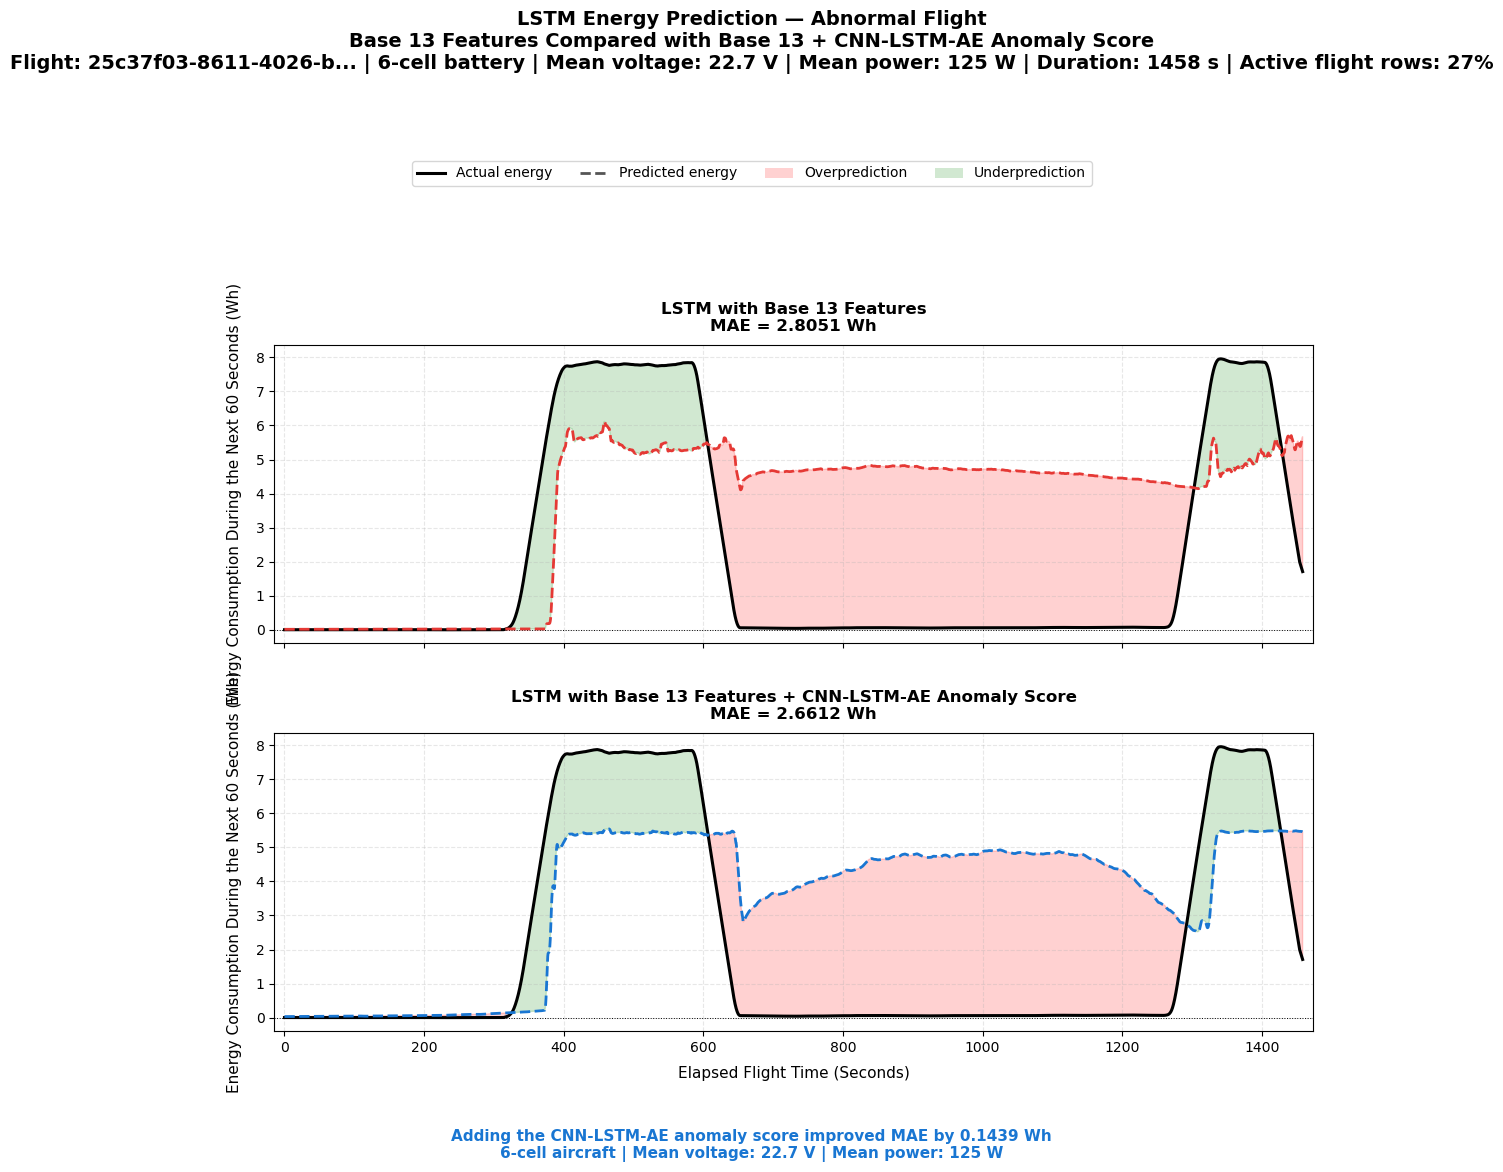

Saved: lstm_base_vs_cnn_abnormal_25c37f03.png
Base 13 MAE: 2.8051 Wh
Base 13 + CNN score MAE: 2.6612 Wh
MAE improvement: +0.1439 Wh


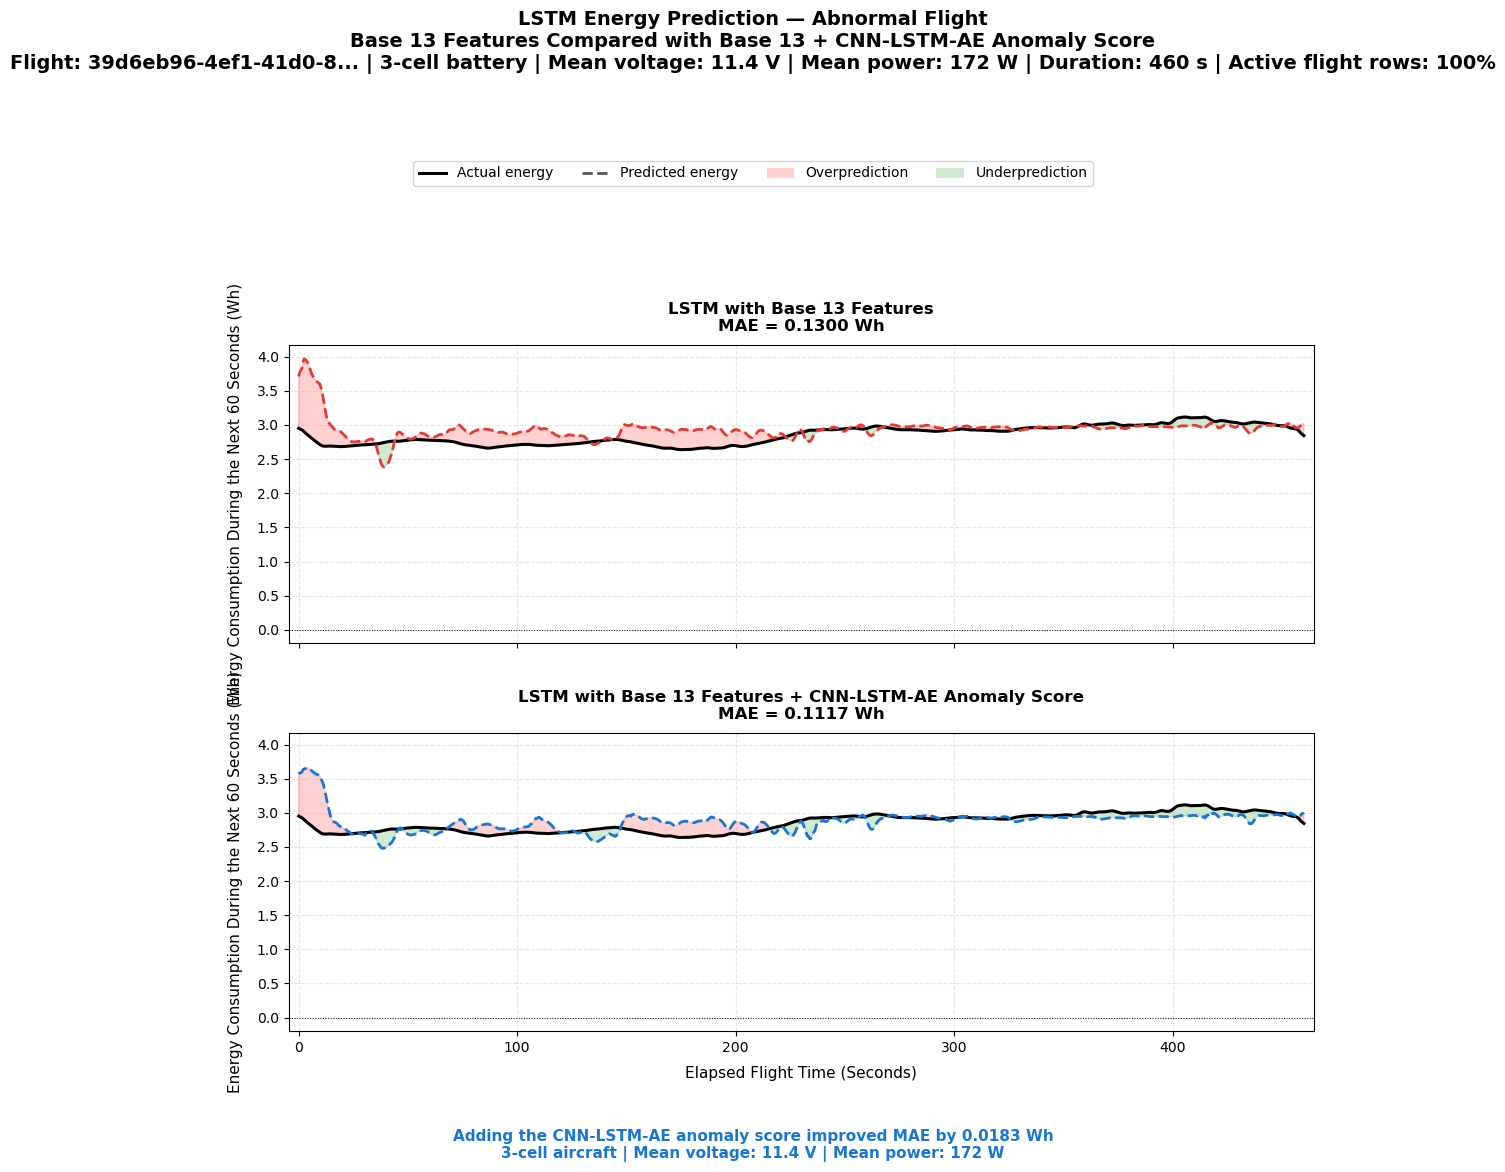

Saved: lstm_base_vs_cnn_abnormal_39d6eb96.png
Base 13 MAE: 0.1300 Wh
Base 13 + CNN score MAE: 0.1117 Wh
MAE improvement: +0.0183 Wh


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.metrics import mean_absolute_error


def plot_base_vs_cnn_comparison_lstm(
    flight_label="abnormal",
    force_flight_id=None,
):
    """
    Compare LSTM energy predictions using:

    1. Base 13 telemetry features
    2. Base 13 telemetry features plus the CNN-LSTM-AE anomaly score

    The two plots are arranged vertically for improved readability.
    """

    # ── Load prediction results ───────────────────────────────
    base_preds = primary_seq_preds["LSTM_Base_13"]
    cnn_preds = primary_seq_preds["LSTM_Base_13+CNN_Score"]

    label_preds = base_preds[
        base_preds["dataset_label"] == flight_label
    ]

    available = label_preds["log_id"].dropna().unique()

    if len(available) == 0:
        print(f"No {flight_label} flights were found.")
        return

    # ── Select flight ─────────────────────────────────────────
    if force_flight_id is not None:
        fid = force_flight_id

        if fid not in available:
            print(
                f"Flight {fid[:8]} was not found among the "
                f"{flight_label} LSTM predictions."
            )
            return

    else:
        # Select the flight with the highest proportion of
        # active rows, where power is greater than 50 W.
        best_active = -1
        fid = available[0]

        for flight_id in available:

            result = get_flight_predictions(
                base_preds,
                raw_ref_full,
                flight_id,
            )

            if result is None:
                continue

            flight_data = full_raw[
                full_raw["log_id"] == flight_id
            ]

            if flight_data.empty:
                continue

            active_ratio = (
                flight_data["power_w"] > 50
            ).mean()

            if active_ratio > best_active:
                best_active = active_ratio
                fid = flight_id

    # ── Align predictions with the raw flight data ────────────
    base_f = get_flight_predictions(
        base_preds,
        raw_ref_full,
        fid,
    )

    cnn_f = get_flight_predictions(
        cnn_preds,
        raw_ref_full,
        fid,
    )

    if base_f is None or cnn_f is None:
        print(f"Could not align flight {fid[:8]}.")
        return

    # Ensure both prediction sets have the same usable length.
    common_length = min(len(base_f), len(cnn_f))

    if common_length == 0:
        print(f"No aligned prediction rows were found for {fid[:8]}.")
        return

    base_f = base_f.iloc[:common_length].reset_index(drop=True)
    cnn_f = cnn_f.iloc[:common_length].reset_index(drop=True)

    # ── Extract prediction values ─────────────────────────────
    t = base_f["time_s_real"].to_numpy()

    y_true = base_f["y_true"].to_numpy()

    y_base = (
        base_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    y_cnn = (
        cnn_f["y_pred"]
        .clip(lower=0)
        .to_numpy()
    )

    # ── Smooth curves for visual clarity ──────────────────────
    smoothing_window = max(
        1,
        len(t) // 150,
    )

    def smooth(values):
        return (
            pd.Series(values)
            .rolling(
                window=smoothing_window,
                center=True,
                min_periods=1,
            )
            .mean()
            .to_numpy()
        )

    y_true_s = smooth(y_true)
    y_base_s = smooth(y_base)
    y_cnn_s = smooth(y_cnn)

    # MAE is calculated using the original, unsmoothed values.
    mae_base = mean_absolute_error(
        y_true,
        y_base,
    )

    mae_cnn = mean_absolute_error(
        y_true,
        y_cnn,
    )

    # ── Flight information ────────────────────────────────────
    flight_info = full_raw[
        full_raw["log_id"] == fid
    ]

    if flight_info.empty:
        print(f"Raw flight information was not found for {fid[:8]}.")
        return

    voltage = (
        flight_info["battery_status__voltage_v"]
        .mean()
    )

    power = flight_info["power_w"].mean()

    cells = int(
        flight_info["battery_status__cell_count"]
        .median()
    )

    active = (
        flight_info["power_w"] > 50
    ).mean()

    duration = t[-1] - t[0] if len(t) > 1 else 0

    # ── Font settings ─────────────────────────────────────────
    plt.rcParams.update({
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
    })

    # ── Create vertically arranged plots ──────────────────────
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(12, 12),
        sharex=True,
        sharey=True,
    )

    fig.suptitle(
        f"LSTM Energy Prediction — {flight_label.title()} Flight\n"
        f"Base 13 Features Compared with Base 13 + "
        f"CNN-LSTM-AE Anomaly Score\n"
        f"Flight: {fid[:20]}... | {cells}-cell battery | "
        f"Mean voltage: {voltage:.1f} V | "
        f"Mean power: {power:.0f} W | "
        f"Duration: {duration:.0f} s | "
        f"Active flight rows: {active:.0%}",
        fontsize=14,
        fontweight="bold",
        y=0.985,
    )

    plot_details = [
        {
            "prediction": y_base_s,
            "title": "LSTM with Base 13 Features",
            "mae": mae_base,
            "line_color": "#E53935",
        },
        {
            "prediction": y_cnn_s,
            "title": (
                "LSTM with Base 13 Features + "
                "CNN-LSTM-AE Anomaly Score"
            ),
            "mae": mae_cnn,
            "line_color": "#1976D2",
        },
    ]

    for ax, details in zip(axes, plot_details):

        predicted = details["prediction"]

        # Areas where predictions were higher than actual values.
        ax.fill_between(
            t,
            predicted,
            y_true_s,
            where=predicted > y_true_s,
            color="red",
            alpha=0.18,
            interpolate=True,
            label="Overprediction",
        )

        # Areas where predictions were lower than actual values.
        ax.fill_between(
            t,
            predicted,
            y_true_s,
            where=predicted < y_true_s,
            color="green",
            alpha=0.18,
            interpolate=True,
            label="Underprediction",
        )

        # Actual energy consumption.
        ax.plot(
            t,
            y_true_s,
            color="black",
            linewidth=2.2,
            label="Actual energy",
            zorder=3,
        )

        # Predicted energy consumption.
        ax.plot(
            t,
            predicted,
            color=details["line_color"],
            linewidth=2.0,
            linestyle="--",
            label="Predicted energy",
            zorder=3,
        )

        ax.axhline(
            y=0,
            color="black",
            linewidth=0.7,
            linestyle=":",
        )

        ax.set_title(
            f"{details['title']}\n"
            f"MAE = {details['mae']:.4f} Wh",
            fontsize=12,
            fontweight="bold",
            pad=10,
        )

        ax.set_ylabel(
            "Energy Consumption During the Next 60 Seconds (Wh)",
            fontsize=11,
            labelpad=10,
        )

        ax.tick_params(
            axis="both",
            labelsize=10,
        )

        ax.grid(
            axis="both",
            linestyle="--",
            alpha=0.30,
            linewidth=0.8,
        )

        ax.margins(x=0.01)

    axes[-1].set_xlabel(
        "Elapsed Flight Time (Seconds)",
        fontsize=11,
        labelpad=8,
    )

    # ── Shared legend ─────────────────────────────────────────
    legend_elements = [
        plt.Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.2,
            label="Actual energy",
        ),
        plt.Line2D(
            [0],
            [0],
            color="#555555",
            linewidth=2.0,
            linestyle="--",
            label="Predicted energy",
        ),
        mpatches.Patch(
            facecolor="red",
            alpha=0.18,
            label="Overprediction",
        ),
        mpatches.Patch(
            facecolor="green",
            alpha=0.18,
            label="Underprediction",
        ),
    ]

    fig.legend(
        handles=legend_elements,
        loc="upper center",
        ncol=4,
        fontsize=10,
        frameon=True,
        bbox_to_anchor=(0.5, 0.865),
    )

    # ── Improvement summary ───────────────────────────────────
    improvement = mae_base - mae_cnn

    if improvement > 0:
        summary_color = "#1976D2"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score improved MAE "
            f"by {improvement:.4f} Wh"
        )

    elif improvement < 0:
        summary_color = "#E53935"
        summary_text = (
            f"Adding the CNN-LSTM-AE anomaly score worsened MAE "
            f"by {abs(improvement):.4f} Wh"
        )

    else:
        summary_color = "#333333"
        summary_text = (
            "Adding the CNN-LSTM-AE anomaly score produced "
            "no change in MAE"
        )

    fig.text(
        0.5,
        0.025,
        f"{summary_text}\n"
        f"{cells}-cell aircraft | "
        f"Mean voltage: {voltage:.1f} V | "
        f"Mean power: {power:.0f} W",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=summary_color,
    )

    # Leave space for the title, shared legend and bottom summary.
    plt.tight_layout(
        rect=[0.05, 0.08, 0.98, 0.82],
        h_pad=3.0,
    )

    # ── Save figure ────────────────────────────────────────────
    filename = (
        PLOT_DIR
        / f"lstm_base_vs_cnn_{flight_label}_{fid[:8]}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    print(f"Saved: {filename.name}")
    print(f"Base 13 MAE: {mae_base:.4f} Wh")
    print(f"Base 13 + CNN score MAE: {mae_cnn:.4f} Wh")
    print(f"MAE improvement: {improvement:+.4f} Wh")


# ── Select the two required flights ───────────────────────────
available_flights = (
    primary_seq_preds["BiLSTM_Base_13"]["log_id"]
    .dropna()
    .unique()
)

fid_6cell = next(
    flight_id
    for flight_id in available_flights
    if flight_id.startswith("25c37f03")
)

fid_3cell = next(
    flight_id
    for flight_id in available_flights
    if flight_id.startswith("39d6eb96")
)

# ── Generate LSTM plots for both abnormal flights ─────────────
plot_base_vs_cnn_comparison_lstm(
    flight_label="abnormal",
    force_flight_id=fid_6cell,
)

plot_base_vs_cnn_comparison_lstm(
    flight_label="abnormal",
    force_flight_id=fid_3cell,
)

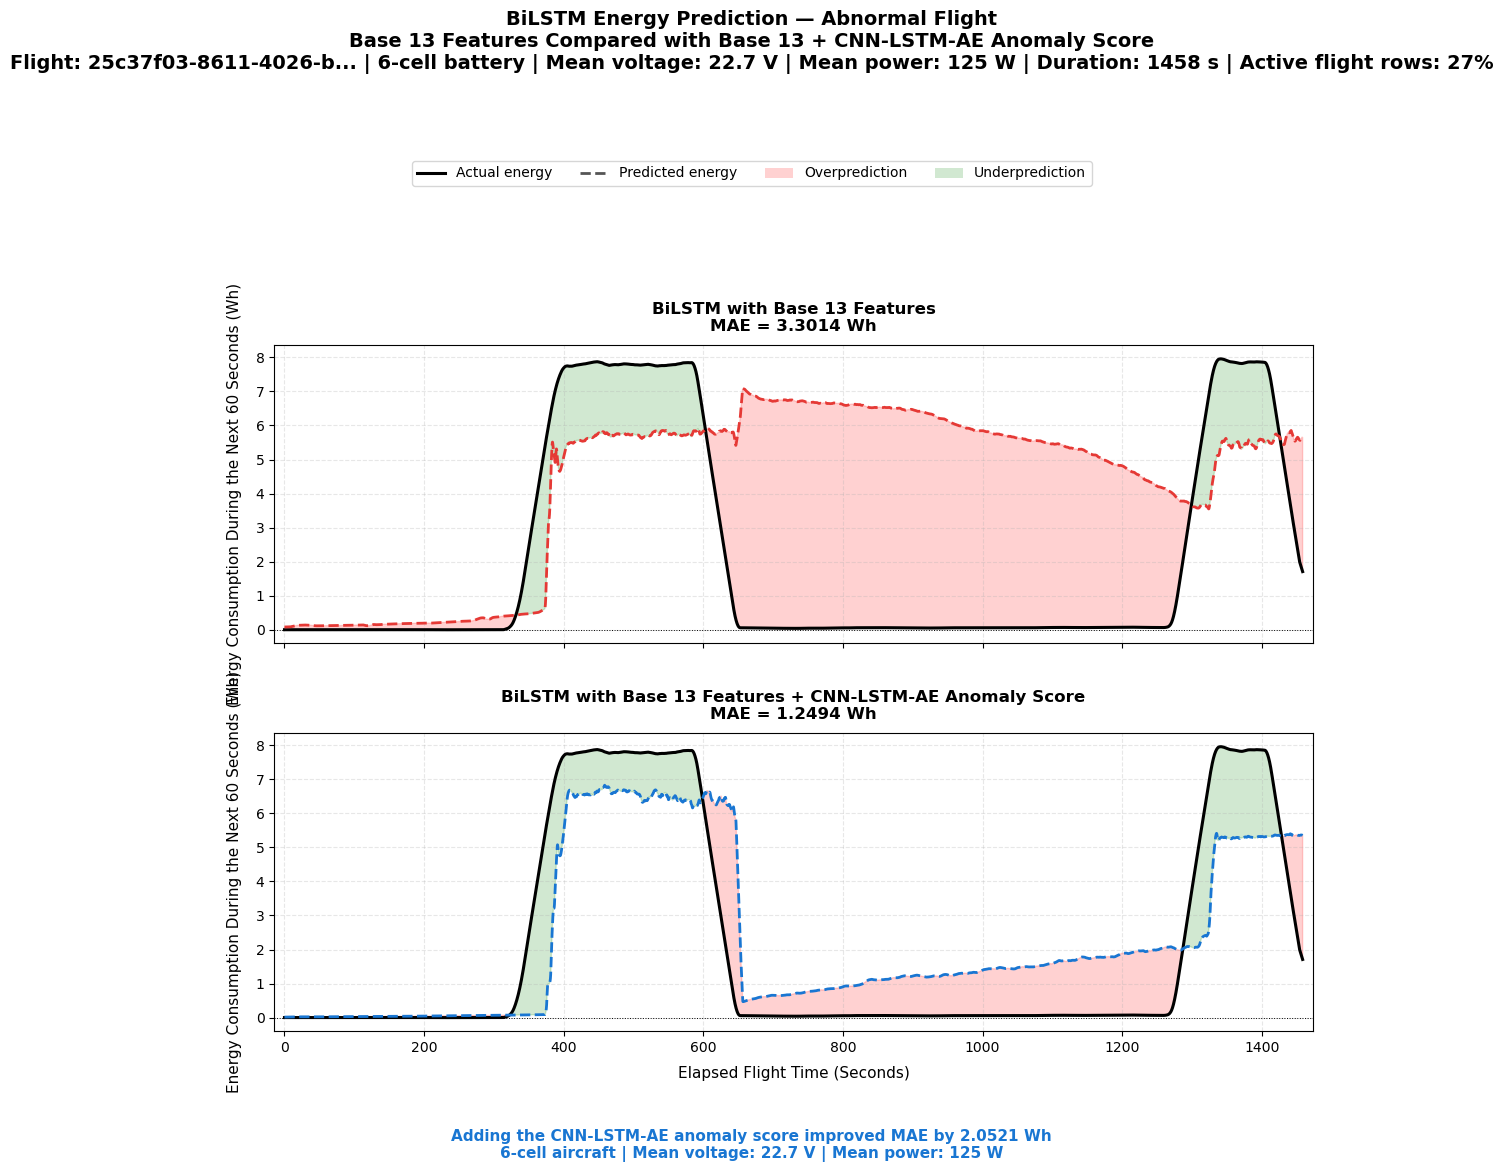

Saved: bilstm_base_vs_cnn_abnormal_25c37f03.png
Base 13 MAE: 3.3014 Wh
Base 13 + CNN score MAE: 1.2494 Wh
MAE improvement: +2.0521 Wh


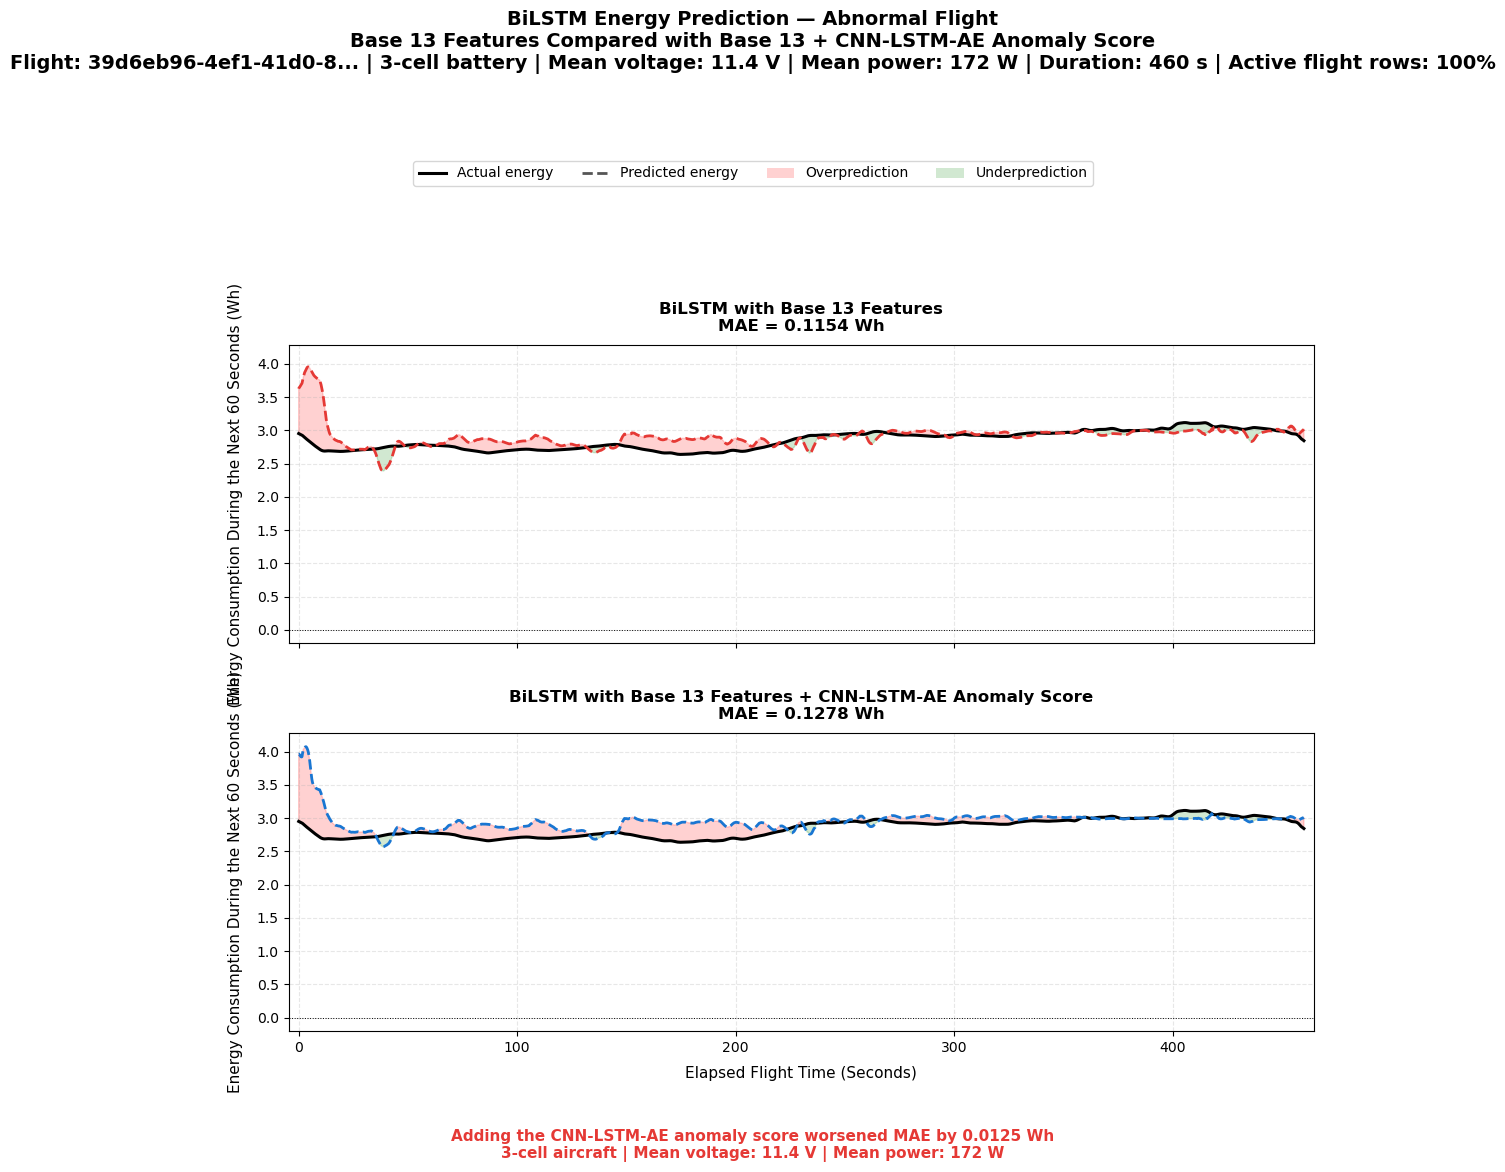

Saved: bilstm_base_vs_cnn_abnormal_39d6eb96.png
Base 13 MAE: 0.1154 Wh
Base 13 + CNN score MAE: 0.1278 Wh
MAE improvement: -0.0125 Wh


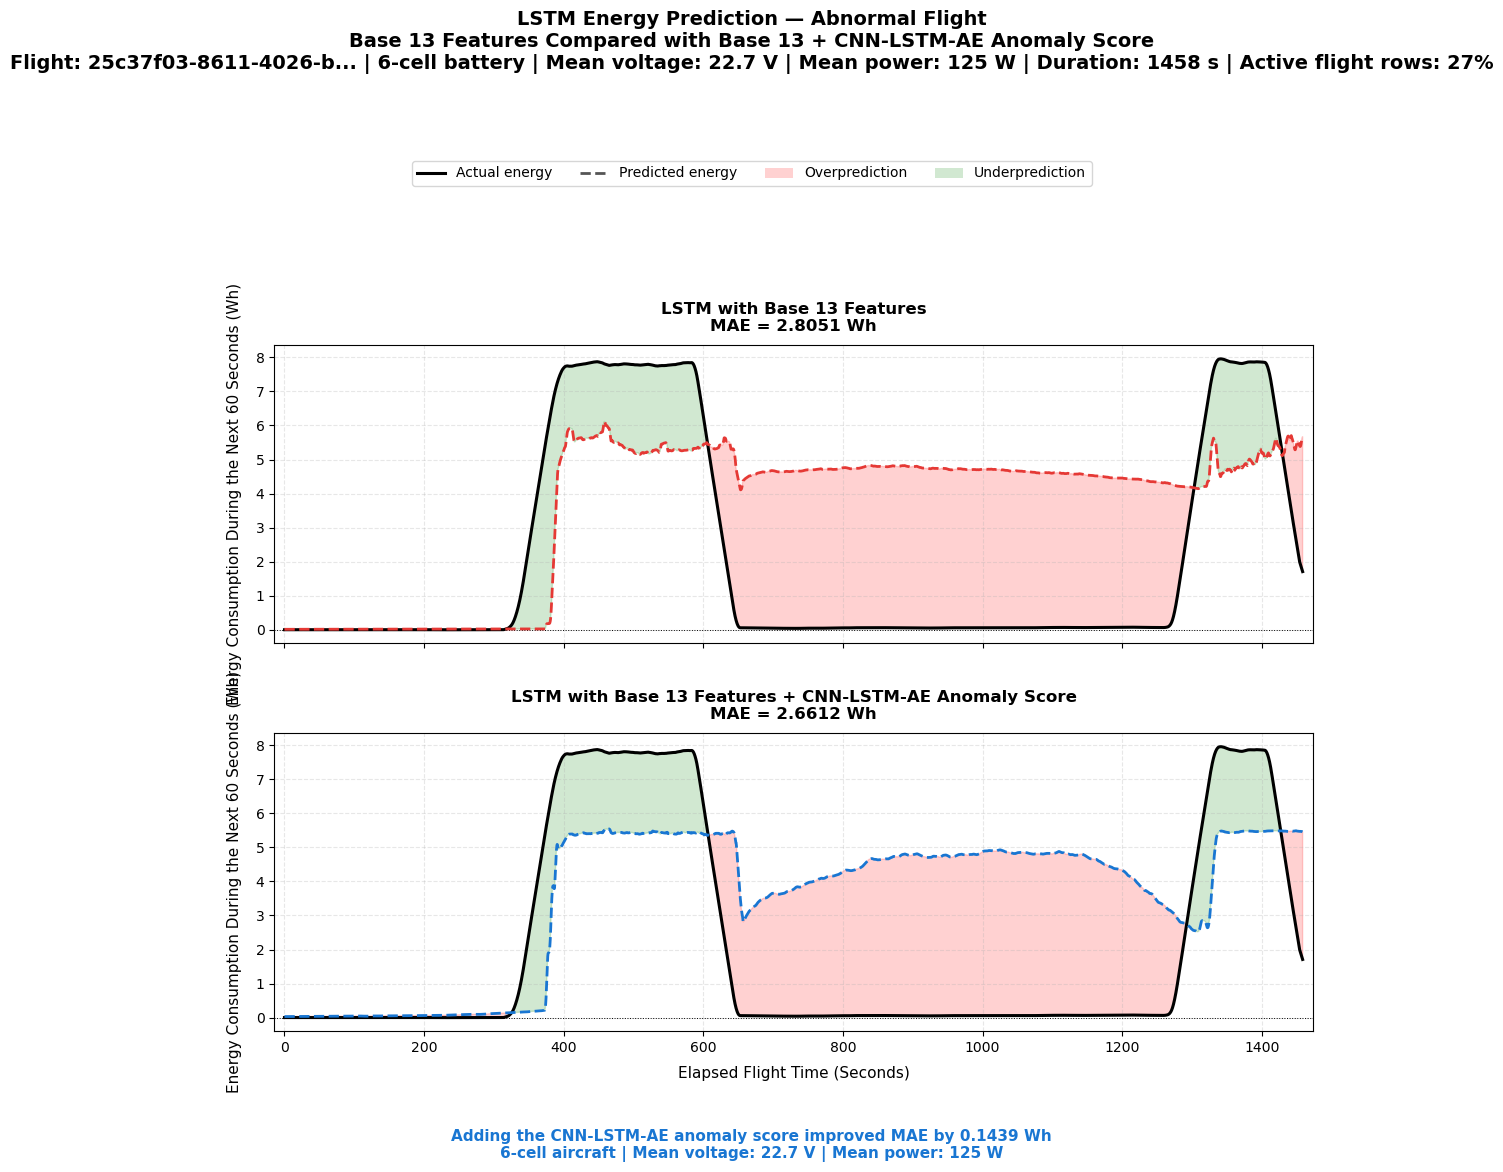

Saved: lstm_base_vs_cnn_abnormal_25c37f03.png
Base 13 MAE: 2.8051 Wh
Base 13 + CNN score MAE: 2.6612 Wh
MAE improvement: +0.1439 Wh


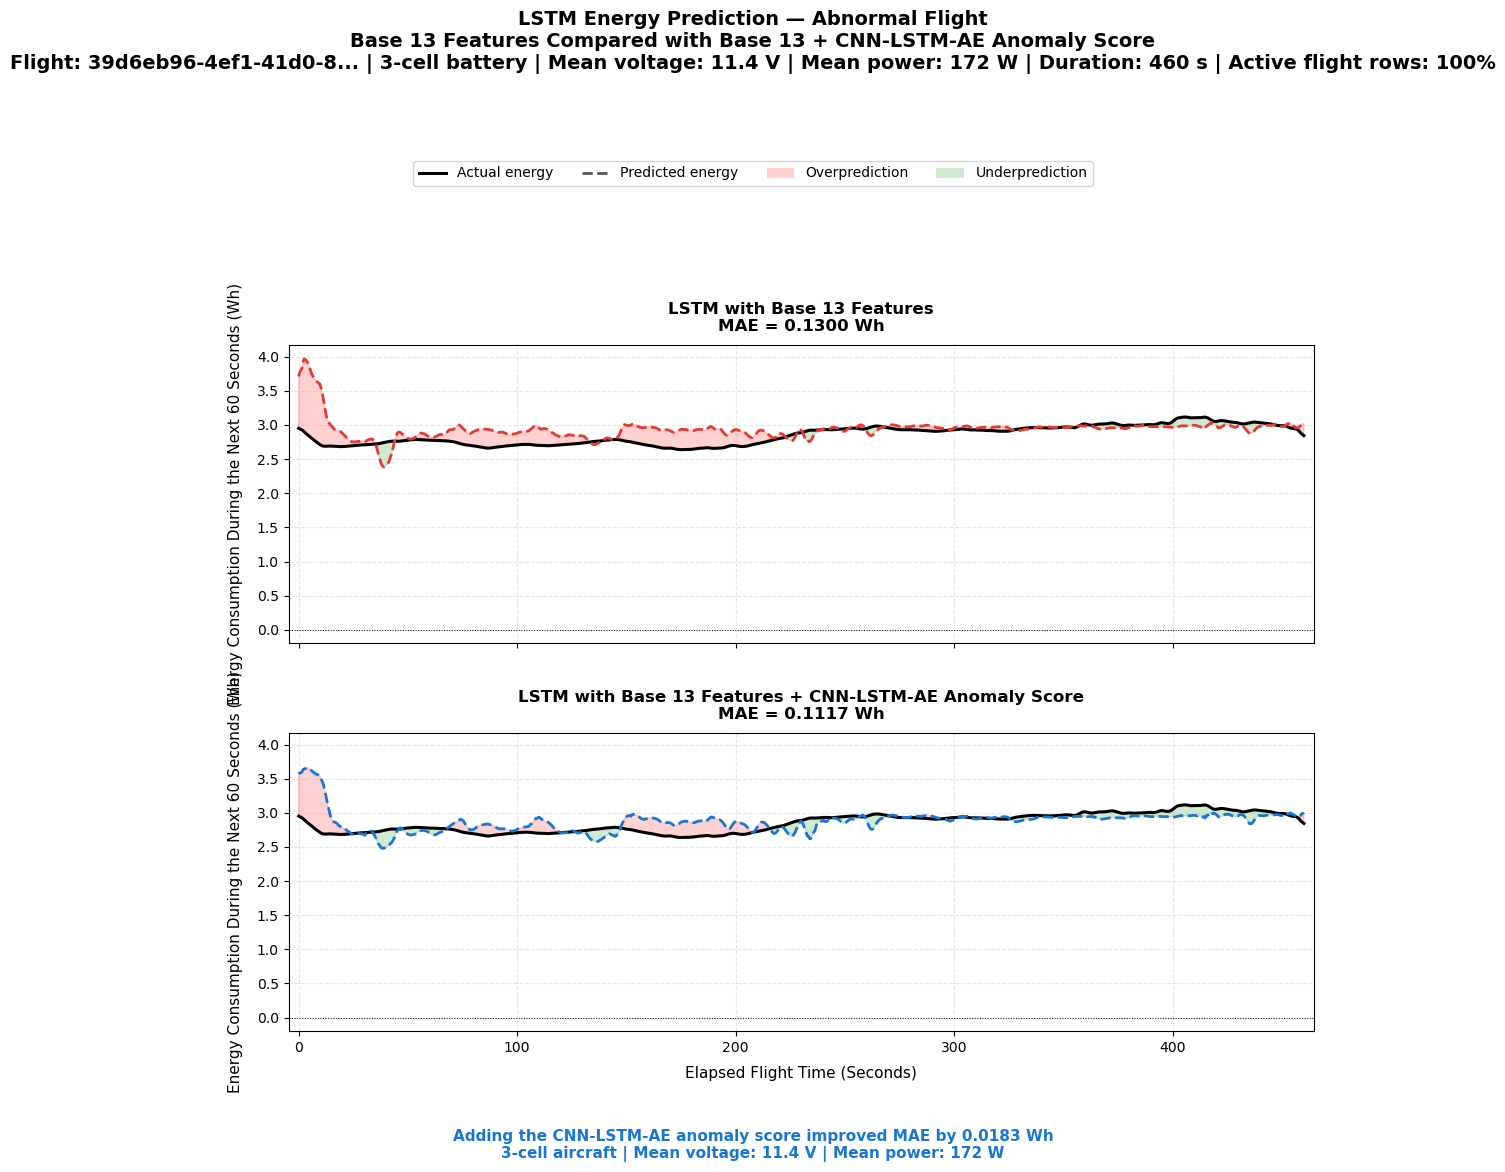

Saved: lstm_base_vs_cnn_abnormal_39d6eb96.png
Base 13 MAE: 0.1300 Wh
Base 13 + CNN score MAE: 0.1117 Wh
MAE improvement: +0.0183 Wh


In [ ]:
fid_6cell = next(f for f in primary_seq_preds["BiLSTM_Base_13"]["log_id"].unique()
                 if f.startswith("25c37f03"))
fid_3cell = next(f for f in primary_seq_preds["BiLSTM_Base_13"]["log_id"].unique()
                 if f.startswith("39d6eb96"))

# BiLSTM plots
plot_base_vs_cnn_comparison("abnormal", force_flight_id=fid_6cell)
plot_base_vs_cnn_comparison("abnormal", force_flight_id=fid_3cell)

# LSTM plots — same flights for direct comparison
plot_base_vs_cnn_comparison_lstm("abnormal", force_flight_id=fid_6cell)
plot_base_vs_cnn_comparison_lstm("abnormal", force_flight_id=fid_3cell)

25c37f03-8611-4026-bb3a-ae908b19fb71


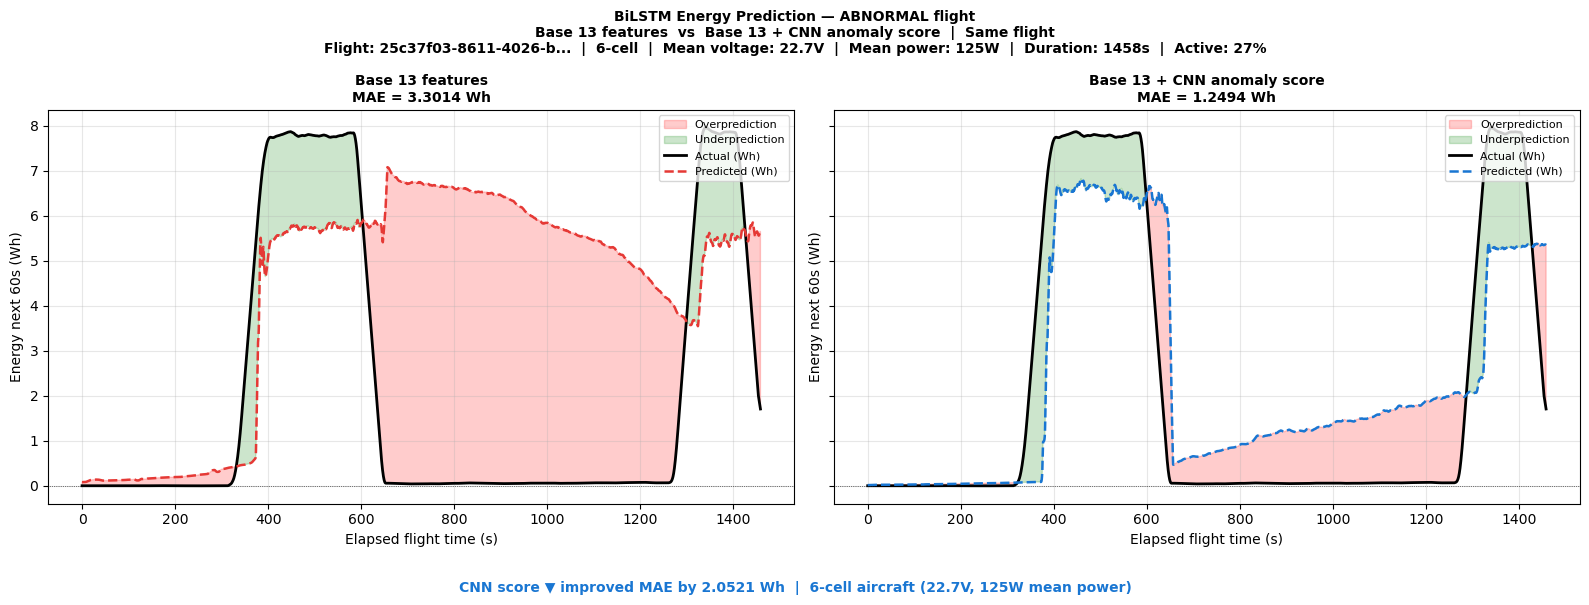

Saved: bilstm_base_vs_cnn_abnormal_25c37f03.png
Base MAE: 3.3014  CNN MAE: 1.2494  Δ: +2.0521 Wh


In [ ]:
fid_full = next(f for f in base_preds["log_id"].unique() 
                if f.startswith("25c37f03"))
print(fid_full)

plot_base_vs_cnn_comparison(
    flight_label="abnormal",
    force_flight_id=fid_full
)

7dc86cfe-ebed-400c-939a-ce5decd323ea


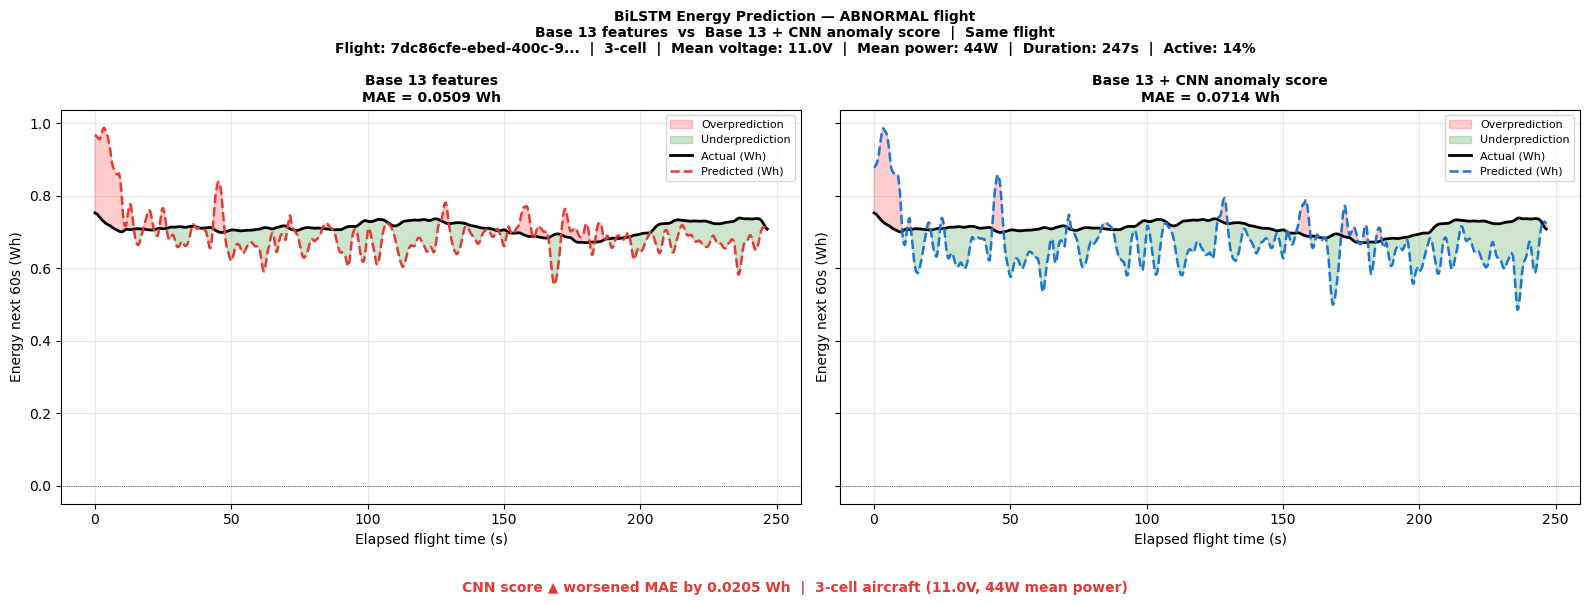

Saved: bilstm_base_vs_cnn_abnormal_7dc86cfe.png
Base MAE: 0.0509  CNN MAE: 0.0714  Δ: -0.0205 Wh


In [ ]:
fid_full = next(f for f in base_preds["log_id"].unique()
                if f.startswith("7dc86cfe"))
print(fid_full)

plot_base_vs_cnn_comparison(
    flight_label="abnormal",
    force_flight_id=fid_full
)

In [ ]:
# check if voltage features exist in all 10 splits
for split_name, seed in SPLITS:
    split_dir = DATA_DIR / split_name
    f = split_dir / f"train_no_dr_scaled_{FILE_VER}_{split_name}.parquet"
    if not f.exists():
        print(f"{split_name}: FILE NOT FOUND")
        continue
    cols = pd.read_parquet(f, columns=None).columns.tolist()
    has_vpc  = "voltage_per_cell" in cols
    has_vfpc = "voltage_filtered_per_cell" in cols
    print(f"{split_name}: voltage_per_cell={has_vpc}  voltage_filtered_per_cell={has_vfpc}")

split_01_seed_11: voltage_per_cell=True  voltage_filtered_per_cell=True
split_02_seed_22: voltage_per_cell=True  voltage_filtered_per_cell=True
split_03_seed_33: voltage_per_cell=True  voltage_filtered_per_cell=True
split_04_seed_44: voltage_per_cell=True  voltage_filtered_per_cell=True
split_05_seed_55: voltage_per_cell=True  voltage_filtered_per_cell=True
split_06_seed_66: voltage_per_cell=True  voltage_filtered_per_cell=True
split_07_seed_77: voltage_per_cell=True  voltage_filtered_per_cell=True
split_08_seed_88: voltage_per_cell=True  voltage_filtered_per_cell=True
split_09_seed_99: voltage_per_cell=True  voltage_filtered_per_cell=True
split_10_seed_111: voltage_per_cell=True  voltage_filtered_per_cell=True


## Idle vs Active phase error analysis

In [ ]:

print("Idle = target < 0.05 Wh  |  Active = target >= 0.05 Wh")

IDLE_THRESHOLD = 0.05
phase_rows = []

for run_key, pred_df in pooled_seq_preds.items():
    model     = run_key.split("_")[0]  # LSTM or BiLSTM
    feat_set  = "Base_13+CNN_Score" if "CNN" in run_key else "Base_13"
    df        = pred_df.copy()
    df["y_pred"] = df["y_pred"].clip(lower=0)

    for ftype in ["normal", "abnormal"]:
        sub = df[df["dataset_label"] == ftype]
        if len(sub) == 0:
            continue

        idle_mask   = sub["y_true"] < IDLE_THRESHOLD
        active_mask = ~idle_mask

        idle_mae   = mean_absolute_error(
            sub.loc[idle_mask,   "y_true"],
            sub.loc[idle_mask,   "y_pred"]) if idle_mask.sum() > 0 else np.nan
        active_mae = mean_absolute_error(
            sub.loc[active_mask, "y_true"],
            sub.loc[active_mask, "y_pred"]) if active_mask.sum() > 0 else np.nan

        ratio = active_mae / idle_mae if idle_mae > 0 else np.nan

        phase_rows.append({
            "Model"       : model,
            "Feature set" : feat_set,
            "Flight type" : ftype,
            "Active MAE"  : round(active_mae, 4),
            "Idle MAE"    : round(idle_mae,   4),
            "Active rows" : int(active_mask.sum()),
            "Idle rows"   : int(idle_mask.sum()),
            "Ratio"       : round(ratio, 1),
        })

phase_df = pd.DataFrame(phase_rows)

for ftype in ["normal", "abnormal"]:
    print(f"\n--- {ftype.upper()} FLIGHTS ---")
    sub = phase_df[phase_df["Flight type"]==ftype].sort_values("Active MAE")
    print(sub[["Model","Feature set","Active MAE",
               "Idle MAE","Ratio","Active rows","Idle rows"]].to_string(index=False))

phase_df.to_csv(OUTPUT_DIR / "07_phase_error_analysis.csv", index=False)
print("\n✓ Saved: 07_phase_error_analysis.csv")

Idle = target < 0.05 Wh  |  Active = target >= 0.05 Wh

--- NORMAL FLIGHTS ---
 Model       Feature set  Active MAE  Idle MAE  Ratio  Active rows  Idle rows
BiLSTM Base_13+CNN_Score      0.2924    0.4800    0.6       844794     152470
BiLSTM           Base_13      0.2980    0.2751    1.1       844794     152470
  LSTM Base_13+CNN_Score      0.3071    0.5179    0.6       844794     152470
  LSTM           Base_13      0.3134    0.4016    0.8       844794     152470

--- ABNORMAL FLIGHTS ---
 Model       Feature set  Active MAE  Idle MAE  Ratio  Active rows  Idle rows
BiLSTM           Base_13      1.3066    0.4586    2.8       473358      22783
  LSTM           Base_13      1.3739    0.5795    2.4       473358      22783
BiLSTM Base_13+CNN_Score      1.3997    0.6055    2.3       473358      22783
  LSTM Base_13+CNN_Score      1.6414    0.4653    3.5       473358      22783

✓ Saved: 07_phase_error_analysis.csv


This confirms the idle overprediction problem on normal flights, idle MAE is HIGHER than active MAE

In [ ]:
# check without split_06
phase_rows_no06 = []
split06_ids = set(pd.read_parquet(
    DATA_DIR / "split_06_seed_66" /
    f"test_no_dr_scaled_{FILE_VER}_split_06_seed_66.parquet"
)["log_id"].unique())

for run_key, pred_df in pooled_seq_preds.items():
    model    = run_key.split("_")[0]
    feat_set = "Base_13+CNN_Score" if "CNN" in run_key else "Base_13"
    df       = pred_df[~pred_df["log_id"].isin(split06_ids)].copy()

    for ftype in ["normal","abnormal"]:
        sub = df[df["dataset_label"]==ftype]
        if len(sub) == 0: continue

        idle_mask   = sub["y_true"] < IDLE_THRESHOLD
        active_mask = ~idle_mask

        idle_mae   = mean_absolute_error(
            sub.loc[idle_mask,  "y_true"],
            sub.loc[idle_mask,  "y_pred"]) if idle_mask.sum() > 0 else np.nan
        active_mae = mean_absolute_error(
            sub.loc[active_mask,"y_true"],
            sub.loc[active_mask,"y_pred"]) if active_mask.sum() > 0 else np.nan

        phase_rows_no06.append({
            "Model"      : model,
            "Feature set": feat_set,
            "Flight type": ftype,
            "Active MAE" : round(active_mae, 4),
            "Idle MAE"   : round(idle_mae,   4),
            "Ratio"      : round(active_mae/idle_mae, 1) if idle_mae > 0 else np.nan,
        })

phase_no06 = pd.DataFrame(phase_rows_no06)
print("IDLE vs ACTIVE — 9 splits (split_06 excluded)")
for ftype in ["normal","abnormal"]:
    print(f"\n--- {ftype.upper()} ---")
    sub = phase_no06[phase_no06["Flight type"]==ftype].sort_values("Active MAE")
    print(sub[["Model","Feature set","Active MAE","Idle MAE","Ratio"]].to_string(index=False))

IDLE vs ACTIVE — 9 splits (split_06 excluded)

--- NORMAL ---
 Model       Feature set  Active MAE  Idle MAE  Ratio
BiLSTM Base_13+CNN_Score      0.3334    0.4887    0.7
BiLSTM           Base_13      0.3419    0.2776    1.2
  LSTM Base_13+CNN_Score      0.3523    0.5295    0.7
  LSTM           Base_13      0.3589    0.4068    0.9

--- ABNORMAL ---
 Model       Feature set  Active MAE  Idle MAE  Ratio
BiLSTM Base_13+CNN_Score      0.8042    0.6055    1.3
  LSTM           Base_13      0.9624    0.5795    1.7
BiLSTM           Base_13      0.9692    0.4586    2.1
  LSTM Base_13+CNN_Score      1.0709    0.4653    2.3


## Negative prediction audit

In [ ]:
neg_rows = []

for run_key, pred_df in pooled_seq_preds.items():
    model    = run_key.split("_")[0]
    feat_set = "Base_13+CNN_Score" if "CNN" in run_key else "Base_13"

    raw_preds  = pred_df["y_pred"].values  # before clipping
    neg_mask   = raw_preds < 0
    neg_count  = neg_mask.sum()
    neg_pct    = neg_count / len(raw_preds) * 100
    neg_min    = float(raw_preds[neg_mask].min()) if neg_count > 0 else 0.0

    # MAE before and after clipping
    mae_raw    = mean_absolute_error(pred_df["y_true"], raw_preds)
    mae_clipped= mean_absolute_error(pred_df["y_true"],
                                      np.clip(raw_preds, 0, None))
    mae_delta  = mae_raw - mae_clipped

    neg_rows.append({
        "Model"        : model,
        "Feature set"  : feat_set,
        "Neg count"    : int(neg_count),
        "Neg %"        : round(neg_pct, 2),
        "Min value"    : round(neg_min, 4),
        "MAE raw"      : round(mae_raw,     4),
        "MAE clipped"  : round(mae_clipped, 4),
        "MAE Δ"        : round(mae_delta,   4),
    })
    print(f"\n{run_key}:")
    print(f"  Negative predictions : {neg_count:,} ({neg_pct:.2f}%)")
    print(f"  Minimum value        : {neg_min:.4f} Wh")
    print(f"  MAE before clip      : {mae_raw:.4f} Wh")
    print(f"  MAE after clip       : {mae_clipped:.4f} Wh")
    print(f"  MAE improvement      : {mae_delta:.4f} Wh")

neg_df = pd.DataFrame(neg_rows)
print("\n" + "=" * 70)
print("SUMMARY TABLE")
print("=" * 70)
print(neg_df[["Model","Feature set","Neg count",
              "Neg %","Min value","MAE Δ"]].to_string(index=False))
neg_df.to_csv(OUTPUT_DIR / "07_negative_prediction_audit.csv", index=False)
print("\n✓ Saved: 07_negative_prediction_audit.csv")


LSTM_Base_13:
  Negative predictions : 0 (0.00%)
  Minimum value        : 0.0000 Wh
  MAE before clip      : 0.6626 Wh
  MAE after clip       : 0.6626 Wh
  MAE improvement      : 0.0000 Wh

LSTM_Base_13+CNN_Score:
  Negative predictions : 0 (0.00%)
  Minimum value        : 0.0000 Wh
  MAE before clip      : 0.7539 Wh
  MAE after clip       : 0.7539 Wh
  MAE improvement      : 0.0000 Wh

BiLSTM_Base_13:
  Negative predictions : 0 (0.00%)
  Minimum value        : 0.0000 Wh
  MAE before clip      : 0.6178 Wh
  MAE after clip       : 0.6178 Wh
  MAE improvement      : 0.0000 Wh

BiLSTM_Base_13+CNN_Score:
  Negative predictions : 0 (0.00%)
  Minimum value        : 0.0000 Wh
  MAE before clip      : 0.6673 Wh
  MAE after clip       : 0.6673 Wh
  MAE improvement      : 0.0000 Wh

SUMMARY TABLE
 Model       Feature set  Neg count  Neg %  Min value  MAE Δ
  LSTM           Base_13          0    0.0        0.0    0.0
  LSTM Base_13+CNN_Score          0    0.0        0.0    0.0
BiLSTM           B